# ДЗ до теми 4 «Основи PyTorch»: прогнозування міцності бетону нейронною мережею

- Студент: Фарід Джафарлі
- Курс: Deep Learning for Computer Vision and NLP (GoIT)
- Дані: [Concrete Strength Prediction](https://www.kaggle.com/datasets/mchilamwar/predict-concrete-strength), файл `ConcreteStrengthData.csv`

Мета роботи: побудувати на PyTorch нейронну мережу, яка прогнозує міцність бетону на стиск (МПа) за складом суміші та віком зразка (дні). Склад суміші задають цемент, доменний шлак, зола-винесення, вода, суперпластифікатор, крупний і дрібний заповнювач (кг/м³). Модель я оцінюю метриками MSE, RMSE, MAE і R², а потім визначаю, які фактори найсильніше впливають на міцність.

Як розділи ноутбука відповідають крокам інструкції та критеріям оцінювання:

| Розділ | Крок інструкції | Критерій |
|---|---|---|
| 1. Імпорт бібліотек, відтворюваність | 1 | |
| 2-3. Завантаження, очищення, EDA (статистика і візуалізація) | 2 | завантаження даних, X / y |
| 4. Дублікати, інженерія ознак, train / val / test, `StandardScaler`, `Dataset` / `DataLoader` | 2 | train/test, нормалізація |
| 5. Клас мережі (`nn.Module`) і обґрунтування архітектури | 3 | модель |
| 6. Loss, оптимізатор, гіперпараметри, цикл навчання з логуванням | 4-5 | налаштування й навчання |
| 7. Експерименти з ознаками, архітектурою, оптимізатором, lr, регуляризацією | 8 | бонус: оптимізація |
| 8. Метрики на тесті, порівняння з базовими моделями, інтерпретація | 6 | оцінка |
| 9. Фактичні vs прогнозовані, залишки, помилки за віком, важливість факторів | 7 | аналіз |
| 10. Криві часткової залежності, карта «цемент × вік», перевірка на нових рецептурах | | бонус: креативний аналіз |
| 11. Висновки, обмеження, шляхи покращення | 9 | висновки |

Вибірки я використовую так: train для навчання ваг, validation для ранньої зупинки й вибору конфігурації, test лише для фінальної оцінки в розділі 8. За тестом не ухвалюється жодне рішення.

## 1. Імпорт бібліотек та налаштування відтворюваності

In [1]:
import copy
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, root_mean_squared_error,
                             mean_absolute_error, r2_score)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Fix all random number generators (python, numpy, torch) for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)       # tiny MLP: one CPU thread is faster (less overhead) and deterministic
DEVICE = torch.device('cpu')   # ~1k rows -> CPU is enough; GPU/MPS would only add transfer overhead

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 160)

NOTEBOOK_START = time.time()
print(f'torch {torch.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | device: {DEVICE}')

torch 2.14.0 | pandas 3.0.6 | scikit-learn 1.9.1 | device: cpu


## 2. Завантаження та очищення даних

Файл читається з відносного шляху `data/ConcreteStrengthData.csv`. Якщо його немає, ноутбук завантажує дані з Kaggle через `kagglehub` (потрібен інтернет).

У сирому файлі назви колонок і значення мають пробіли в кінці (`'CementComponent '`, `'540.0 '`), а рядки закінчуються `\r\n`. Тому назви колонок я очищаю через `str.strip()`, а нечислові колонки (якщо такі з'являться) примусово переводжу в числа. Для графіків колонки перейменовано на короткі назви.

In [2]:
DATA_FILE = Path('data') / 'ConcreteStrengthData.csv'

if DATA_FILE.exists():
    data_path = DATA_FILE
else:
    # fallback: download the public dataset from Kaggle (needs internet)
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download('mchilamwar/predict-concrete-strength'))
    data_path = next(dataset_dir.rglob('*.csv'))

raw = pd.read_csv(data_path)
print('Файл:', data_path)
print('Сирі назви колонок:', list(raw.columns))

Файл: data/ConcreteStrengthData.csv
Сирі назви колонок: ['CementComponent ', 'BlastFurnaceSlag', 'FlyAshComponent', 'WaterComponent', 'SuperplasticizerComponent', 'CoarseAggregateComponent', 'FineAggregateComponent', 'AgeInDays', 'Strength']


In [3]:
RENAME = {
    'CementComponent': 'Cement',
    'BlastFurnaceSlag': 'Slag',
    'FlyAshComponent': 'FlyAsh',
    'WaterComponent': 'Water',
    'SuperplasticizerComponent': 'Superplasticizer',
    'CoarseAggregateComponent': 'CoarseAggregate',
    'FineAggregateComponent': 'FineAggregate',
    'AgeInDays': 'Age',
    'Strength': 'Strength',
}

df = raw.copy()
df.columns = df.columns.str.strip()                  # 'CementComponent ' -> 'CementComponent'
for col in df.columns:                               # values may carry trailing spaces as well
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')
df = df.rename(columns=RENAME)

TARGET = 'Strength'
BASE_FEATURES = [c for c in df.columns if c != TARGET]        # 8 predictors
MIX_COLS = [c for c in BASE_FEATURES if c != 'Age']           # 7 mix components = "recipe"
UNITS = {c: 'кг/м³' for c in MIX_COLS} | {'Age': 'дні', 'Strength': 'МПа'}

print('Очищені назви:', list(df.columns))
df.head()

Очищені назви: ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age', 'Strength']


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,79.990
1,540.000,0.000,0.000,162.000,2.500,"1,055.000",676.000,28,61.890
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,40.270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,41.050
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,44.300


Опис змінних (кількості компонентів у кг на 1 м³ суміші):

| Колонка | Зміст | Одиниці |
|---|---|---|
| `Cement` | портландцемент, основне в'яжуче | кг/м³ |
| `Slag` | доменний гранульований шлак (частково замінює цемент, латентно-гідравлічний) | кг/м³ |
| `FlyAsh` | зола-винесення (пуцоланова добавка, повільно набирає міцність) | кг/м³ |
| `Water` | вода замішування | кг/м³ |
| `Superplasticizer` | суперпластифікатор (дозволяє зменшити воду при тій самій рухливості) | кг/м³ |
| `CoarseAggregate` | крупний заповнювач (щебінь) | кг/м³ |
| `FineAggregate` | дрібний заповнювач (пісок) | кг/м³ |
| `Age` | вік зразка на момент випробування | дні |
| `Strength` | цільова змінна: міцність на стиск | МПа |

## 3. Попередній аналіз даних (EDA)

### 3.1 Розмір, типи, статистичний опис

In [4]:
print('Розмір таблиці:', df.shape)
print()
df.info()

Розмір таблиці: (1030, 9)

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Cement            1030 non-null   float64
 1   Slag              1030 non-null   float64
 2   FlyAsh            1030 non-null   float64
 3   Water             1030 non-null   float64
 4   Superplasticizer  1030 non-null   float64
 5   CoarseAggregate   1030 non-null   float64
 6   FineAggregate     1030 non-null   float64
 7   Age               1030 non-null   int64  
 8   Strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
desc = df.describe().T
desc['skew'] = df.skew()
desc['zeros, %'] = (df == 0).mean() * 100
desc

,count,mean,std,min,25%,50%,75%,max,skew,"zeros, %"
Cement,"1,030.000",281.168,104.506,102.000,192.375,272.900,350.000,540.000,0.509,0.000
Slag,"1,030.000",73.896,86.279,0.000,0.000,22.000,142.950,359.400,0.801,45.728
FlyAsh,"1,030.000",54.188,63.997,0.000,0.000,0.000,118.300,200.100,0.537,54.951
Water,"1,030.000",181.567,21.354,121.800,164.900,185.000,192.000,247.000,0.075,0.000
Superplasticizer,"1,030.000",6.205,5.974,0.000,0.000,6.400,10.200,32.200,0.907,36.796
CoarseAggregate,"1,030.000",972.919,77.754,801.000,932.000,968.000,"1,029.400","1,145.000",-0.040,0.000
FineAggregate,"1,030.000",773.580,80.176,594.000,730.950,779.500,824.000,992.600,-0.253,0.000
Age,"1,030.000",45.662,63.170,1.000,7.000,28.000,56.000,365.000,3.269,0.000
Strength,"1,030.000",35.818,16.706,2.330,23.710,34.445,46.135,82.600,0.417,0.000


- Усі 9 колонок числові (`float64` / `int64`), категоріальних ознак немає.
- Масштаби ознак дуже різні: `Superplasticizer` 0-32, `Cement` 102-540, `CoarseAggregate` 801-1145 кг/м³. Тому перед нейромережею ознаки треба стандартизувати.
- У `Slag`, `FlyAsh` і `Superplasticizer` багато нулів (≈ 46 %, 55 %, 37 %), бо частина сумішей цих добавок не містить.
- `Age` має сильну правосторонню асиметрію (skew ≈ 3.3).

### 3.2 Пропуски та дублікати

In [6]:
print('Пропущені значення по колонках:')
print(df.isna().sum().to_string())

n_dup = df.duplicated().sum()
print(f'\nПовних дублікатів рядків: {n_dup} ({n_dup / len(df):.1%})')
df[df.duplicated(keep=False)].sort_values(BASE_FEATURES).head(8)

Пропущені значення по колонках:
Cement              0
Slag                0
FlyAsh              0
Water               0
Superplasticizer    0
CoarseAggregate     0
FineAggregate       0
Age                 0
Strength            0

Повних дублікатів рядків: 25 (2.4%)


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
801,252.000,0.000,0.000,185.000,0.000,"1,111.000",784.000,28,19.690
809,252.000,0.000,0.000,185.000,0.000,"1,111.000",784.000,28,19.690
83,362.600,189.000,0.000,164.900,11.600,944.700,755.800,3,35.300
86,362.600,189.000,0.000,164.900,11.600,944.700,755.800,3,35.300
88,362.600,189.000,0.000,164.900,11.600,944.700,755.800,3,35.300
91,362.600,189.000,0.000,164.900,11.600,944.700,755.800,3,35.300
106,362.600,189.000,0.000,164.900,11.600,944.700,755.800,7,55.900
109,362.600,189.000,0.000,164.900,11.600,944.700,755.800,7,55.900


In [7]:
# The same recipe + age can have DIFFERENT strength (repeated lab tests) -> measurement noise
dedup = df.drop_duplicates()
grp = dedup.groupby(BASE_FEATURES)[TARGET]
rep_groups = grp.agg(['count', 'min', 'max', 'std'])[grp.count() > 1].reset_index()

n_recipes = df[MIX_COLS].drop_duplicates().shape[0]
ages_per_recipe = dedup.groupby(MIX_COLS)['Age'].nunique()

print(f'Унікальних рецептур (7 компонентів): {n_recipes}; '
      f'рецептур, випробуваних у кількох віках: {(ages_per_recipe > 1).sum()}')
print(f'Груп «однакова рецептура + вік» з різною міцністю: {len(rep_groups)}; '
      f'медіанний розкид σ = {rep_groups["std"].median():.2f} МПа')
display(rep_groups.drop(columns=['CoarseAggregate', 'FineAggregate']))

print('Майже ідентичні суміші (відрізняються лише крупним заповнювачем на 15 кг):')
display(df.loc[[0, 1]])

Унікальних рецептур (7 компонентів): 427; рецептур, випробуваних у кількох віках: 181
Груп «однакова рецептура + вік» з різною міцністю: 9; медіанний розкид σ = 3.14 МПа


,Cement,Slag,FlyAsh,Water,Superplasticizer,Age,count,min,max,std
0,359.000,19.000,141.000,154.000,10.900,3,2,23.640,25.120,1.047
1,359.000,19.000,141.000,154.000,10.900,7,2,35.750,38.610,2.022
2,359.000,19.000,141.000,154.000,10.900,28,2,59.490,62.940,2.440
3,359.000,19.000,141.000,154.000,10.900,56,2,66.780,68.750,1.393
4,362.600,189.000,0.000,164.900,11.600,7,2,22.900,55.900,23.335
5,446.000,24.000,79.000,162.000,11.600,3,3,23.350,35.360,6.506
6,446.000,24.000,79.000,162.000,11.600,7,3,38.020,52.010,7.734
7,446.000,24.000,79.000,162.000,11.600,28,3,44.420,57.030,6.307
8,446.000,24.000,79.000,162.000,11.600,56,3,55.250,61.070,3.135


Майже ідентичні суміші (відрізняються лише крупним заповнювачем на 15 кг):


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,79.990
1,540.000,0.000,0.000,162.000,2.500,"1,055.000",676.000,28,61.890


- Пропусків немає.
- Є 25 повних дублікатів (2.4 %), у яких збігаються всі 9 значень. Що з ними робити, вирішую в розділі 4.1.
- У даних є шум вимірювань, який не прибрати. Повторні випробування тієї самої суміші в тому самому віці відрізняються на 1-8 МПа (медіанна σ ≈ 3 МПа). Дві майже однакові суміші з 540 кг цементу (рядки 0 і 1) мають 80.0 і 61.9 МПа. У парі 22.9 / 55.9 МПа (362.6 кг цементу, 7 діб) майже напевно є помилка запису, але без першоджерела я її не видаляю. Через такий шум навіть ідеальна модель матиме RMSE у кілька МПа.
- На 1030 рядків припадає лише 427 унікальних рецептур: більшість сумішей випробували в кількох віках. Від цього залежить, як коректно оцінювати модель (див. 10.3).

### 3.3 Розподіл цільової змінної

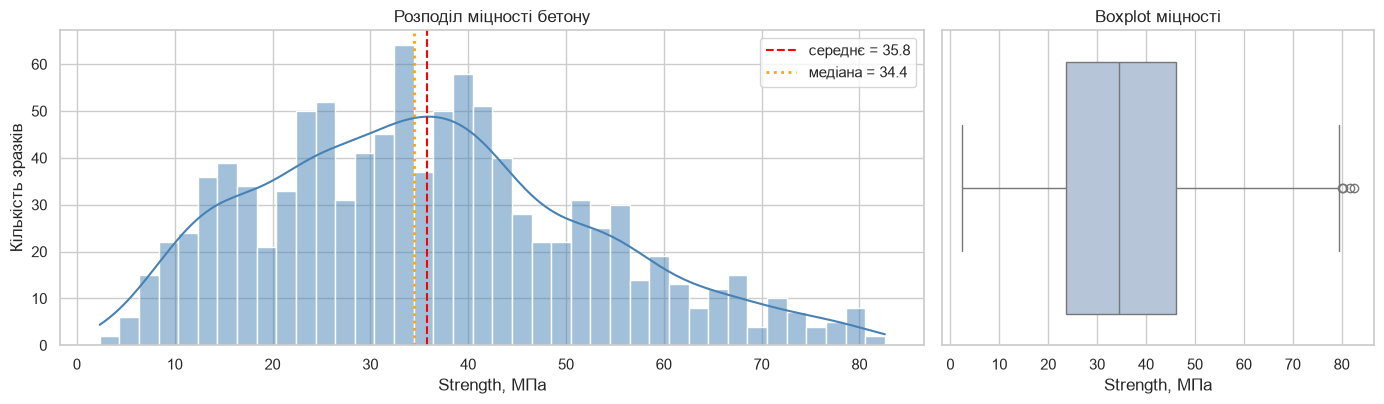

skew = 0.42, kurtosis = -0.31, викидів за правилом 1.5·IQR: 4


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [2, 1]})
sns.histplot(df[TARGET], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df[TARGET].mean(), color='red', ls='--', label=f'середнє = {df[TARGET].mean():.1f}')
axes[0].axvline(df[TARGET].median(), color='orange', ls=':', lw=2, label=f'медіана = {df[TARGET].median():.1f}')
axes[0].set(title='Розподіл міцності бетону', xlabel='Strength, МПа', ylabel='Кількість зразків')
axes[0].legend()
sns.boxplot(x=df[TARGET], ax=axes[1], color='lightsteelblue')
axes[1].set(title='Boxplot міцності', xlabel='Strength, МПа')
plt.tight_layout()
plt.show()

q1, q3 = df[TARGET].quantile([0.25, 0.75])
n_out = ((df[TARGET] < q1 - 1.5 * (q3 - q1)) | (df[TARGET] > q3 + 1.5 * (q3 - q1))).sum()
print(f'skew = {df[TARGET].skew():.2f}, kurtosis = {df[TARGET].kurt():.2f}, '
      f'викидів за правилом 1.5·IQR: {n_out}')

Ціль розподілена майже симетрично (skew ≈ 0.4): діапазон 2.3-82.6 МПа, середнє ≈ 35.8 МПа, σ ≈ 16.7 МПа. Кілька «викидів» зверху належать реальним високоміцним бетонам (багато цементу, суперпластифікатор, великий вік). Помилками вони не є, тому я їх залишаю. Логарифмувати ціль не потрібно.

Для орієнтиру: модель, яка завжди прогнозує середнє, матиме MSE ≈ σ² ≈ 280 МПа². Рівень «відмінно» (MSE < 35) означає, що модель пояснює ≈ 88 % дисперсії.

### 3.4 Розподіли ознак

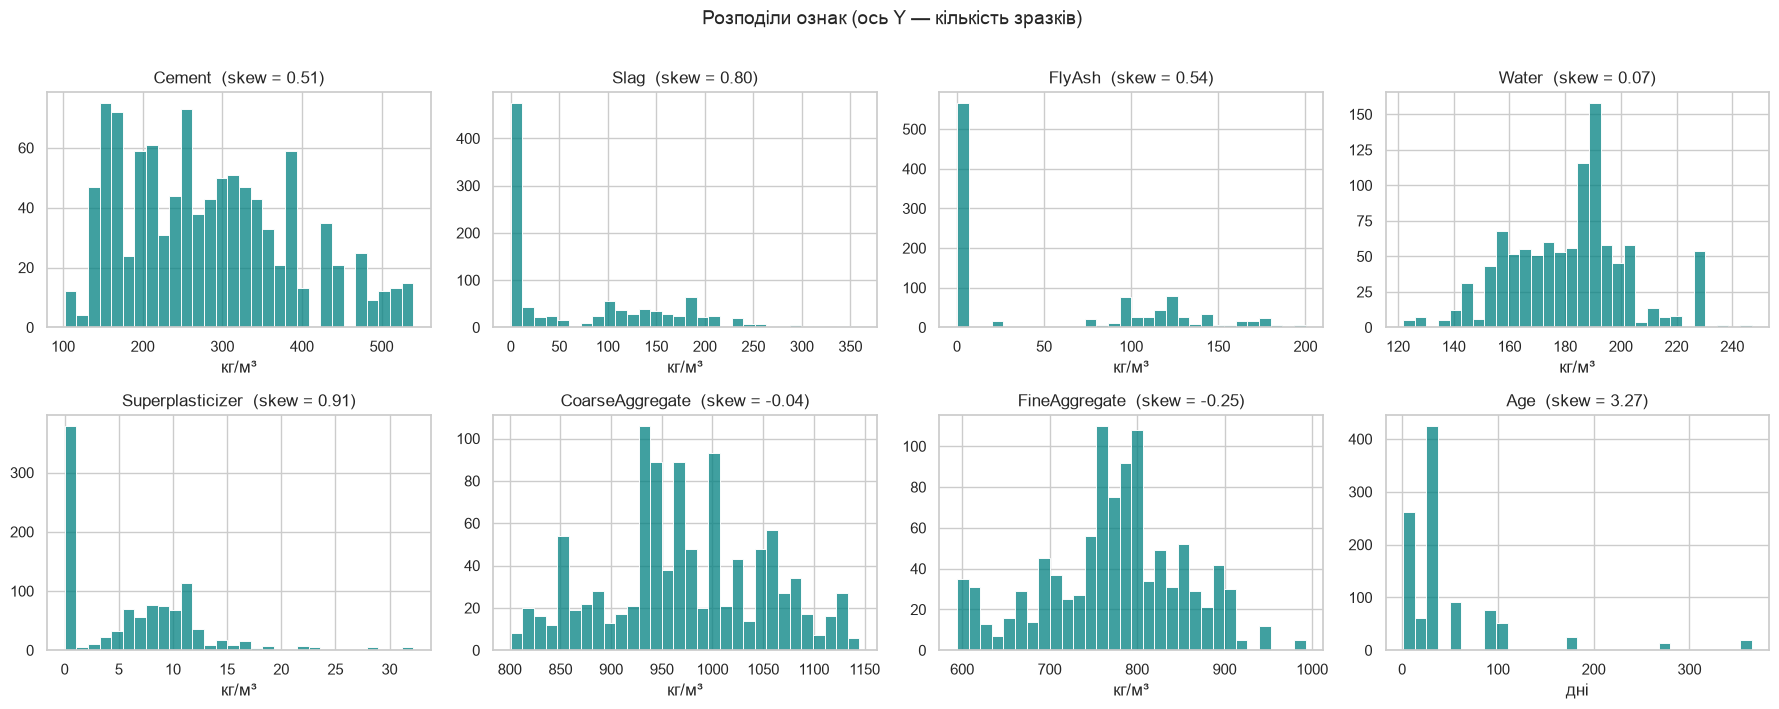

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), BASE_FEATURES):
    sns.histplot(df[col], bins=30, ax=ax, color='teal')
    ax.set_title(f'{col}  (skew = {df[col].skew():.2f})')
    ax.set_xlabel(UNITS[col])
    ax.set_ylabel('')
fig.suptitle('Розподіли ознак (ось Y — кількість зразків)', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### 3.5 Вік зразка: дискретний і скошений розподіл

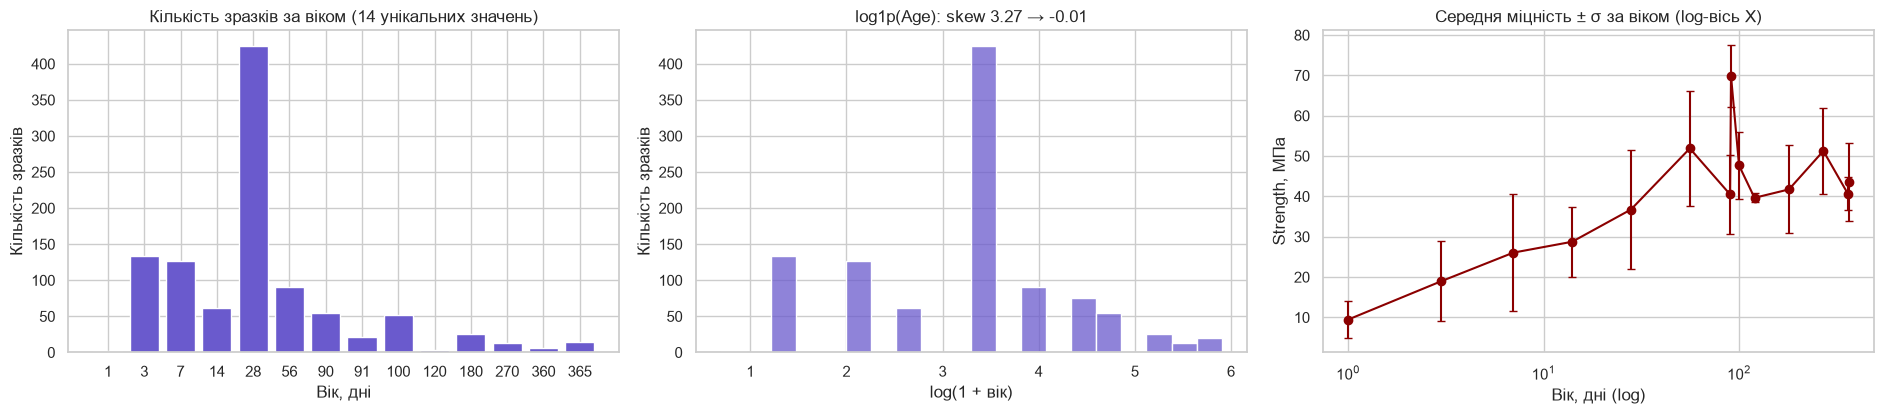

Частка 28-добових зразків: 41.3%; старших за 100 днів: 6.0%


In [10]:
age_counts = df['Age'].value_counts().sort_index()
age_stats = df.groupby('Age')[TARGET].agg(['mean', 'std', 'count'])

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
axes[0].bar(age_counts.index.astype(str), age_counts.values, color='slateblue')
axes[0].set(title=f'Кількість зразків за віком ({len(age_counts)} унікальних значень)',
            xlabel='Вік, дні', ylabel='Кількість зразків')
sns.histplot(np.log1p(df['Age']), bins=20, ax=axes[1], color='slateblue')
axes[1].set(title=f"log1p(Age): skew {df['Age'].skew():.2f} → {np.log1p(df['Age']).skew():.2f}",
            xlabel='log(1 + вік)', ylabel='Кількість зразків')
axes[2].errorbar(age_stats.index, age_stats['mean'], yerr=age_stats['std'], fmt='o-', capsize=3, color='darkred')
axes[2].set_xscale('log')
axes[2].set(title='Середня міцність ± σ за віком (log-вісь X)', xlabel='Вік, дні (log)', ylabel='Strength, МПа')
plt.tight_layout()
plt.show()

print(f"Частка 28-добових зразків: {(df['Age'] == 28).mean():.1%}; "
      f"старших за 100 днів: {(df['Age'] > 100).mean():.1%}")

- `Age` має лише 14 дискретних значень (1, 3, 7, 14, 28, 56, 90, 91, 100, 120, 180, 270, 360, 365). Близько 41 % зразків мають стандартний вік 28 діб, а старших за 100 діб лише ≈ 6 %.
- Міцність росте з віком нелінійно: швидко в перші 28 діб (гідратація цементу), потім повільно, з виходом на плато. На log-осі залежність близька до лінійної.
- Після 56 діб середні скачуть: пік на 91 добі, «провал» на 90 і 120-365. Причина в змішуванні віку зі складом, фізичного ефекту тут немає. На 91 добу випробовували переважно високоцементні суміші з суперпластифікатором (≈ 392 кг цементу, 15 кг добавки), а в 90 і 120-365 діб старі рецептури без суперпластифікатора з великою кількістю води (≈ 200-219 кг). Тому вплив віку треба оцінювати за інших рівних умов. Це зробить модель (див. PDP у 10.1).
- Звідси природна інженерна ознака `LogAge = log1p(Age)`. Вона «розтягує» ранній вік, де відбуваються основні зміни, і «стискає» довгий хвіст 180-365 діб, щоб рідкісні старі зразки не домінували у стандартизованій ознаці. Ефект я перевіряю експериментом у розділі 7.

### 3.6 Кореляції

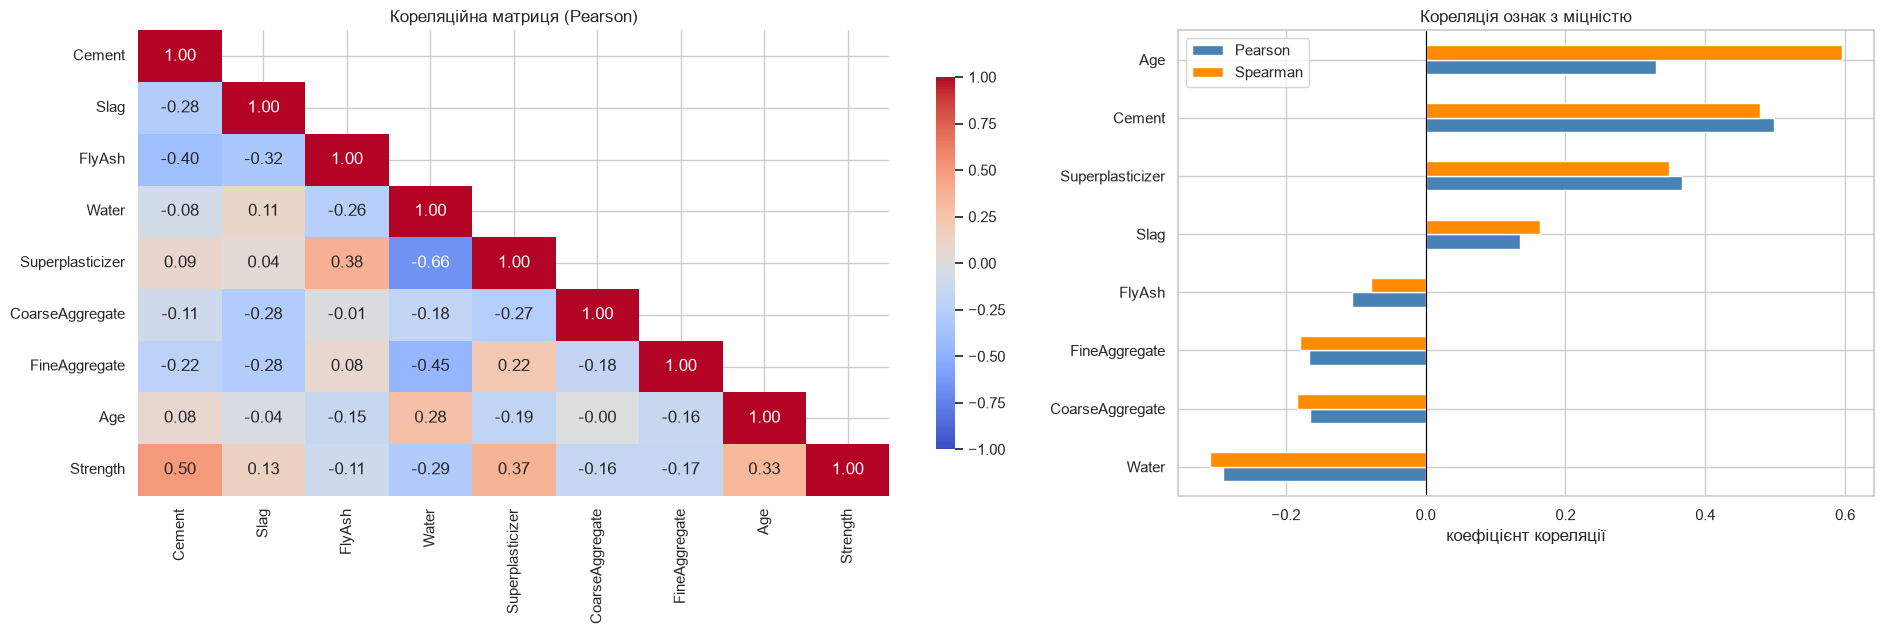

,Pearson,Spearman
Cement,0.498,0.478
Superplasticizer,0.366,0.348
Age,0.329,0.596
Slag,0.135,0.164
FlyAsh,-0.106,-0.078
CoarseAggregate,-0.165,-0.184
FineAggregate,-0.167,-0.180
Water,-0.290,-0.308


In [11]:
corr = df.corr(method='pearson')
corr_target = pd.DataFrame({
    'Pearson': corr[TARGET].drop(TARGET),
    'Spearman': df.corr(method='spearman')[TARGET].drop(TARGET),
}).sort_values('Spearman')

fig, axes = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={'width_ratios': [1.35, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Кореляційна матриця (Pearson)')
corr_target.plot.barh(ax=axes[1], color=['steelblue', 'darkorange'])
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set(title='Кореляція ознак з міцністю', xlabel='коефіцієнт кореляції')
plt.tight_layout()
plt.show()
corr_target.sort_values('Pearson', ascending=False)

- Найсильніший лінійний зв'язок з міцністю має `Cement` (r ≈ 0.50), далі йдуть `Superplasticizer` (0.37) і `Age` (0.33). У `Water` зв'язок від'ємний (−0.29).
- Для `Age` коефіцієнт Спірмена (≈ 0.60) майже вдвічі більший за коефіцієнт Пірсона. Отже, зв'язок монотонний, але нелінійний, і це ще один аргумент на користь `log1p(Age)` та нелінійної моделі.
- Між самими ознаками є помітні залежності: `Water` ↔ `Superplasticizer` (−0.66, бо суперпластифікатор дозволяє зменшити воду), `Water` ↔ `FineAggregate` (−0.45), `FlyAsh` ↔ `Cement` (−0.40, зола замінює частину цементу). Сильної мультиколінеарності (|r| > 0.8) немає.
- Жодна ознака окремо не пояснює більше ≈ 25 % дисперсії (r² ≤ 0.25). Міцність залежить від комбінації факторів, тому нейромережа з прихованими шарами тут доречна.

### 3.7 Діаграми розсіювання основних факторів

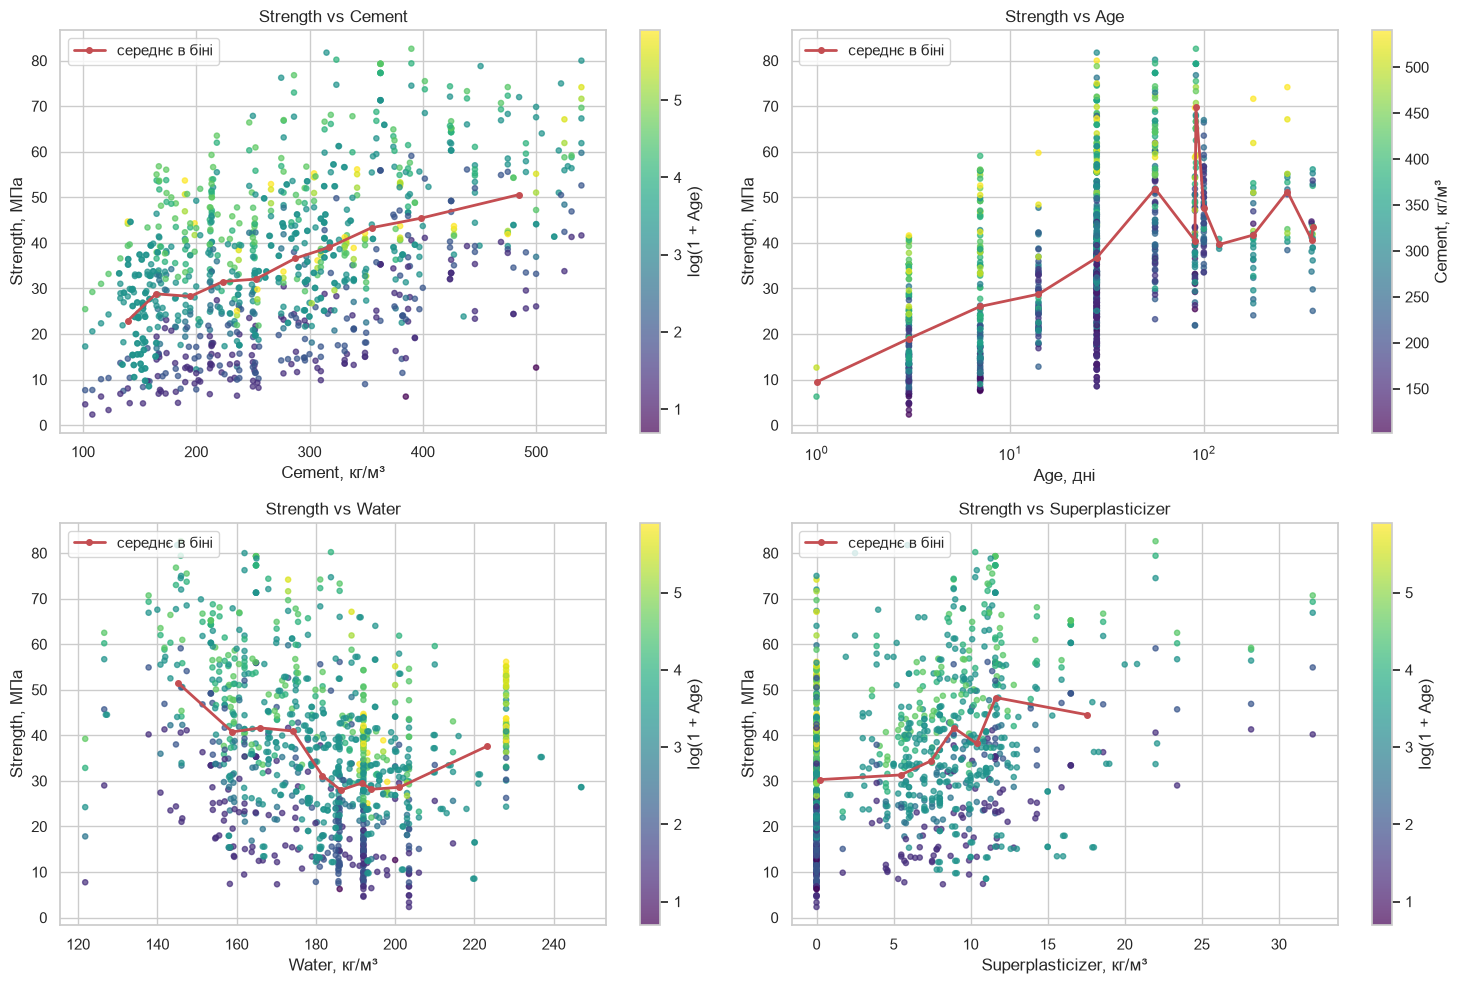

In [12]:
def binned_mean(frame, col, q=10):
    """Mean target inside quantile bins of `col` (per unique value for Age) — a trend line for scatter plots."""
    keys = frame[col] if col == 'Age' else pd.qcut(frame[col], q=q, duplicates='drop')
    return frame.groupby(keys, observed=True).agg(x=(col, 'mean'), y=(TARGET, 'mean'))


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panels = [('Cement', 'Age'), ('Age', 'Cement'), ('Water', 'Age'), ('Superplasticizer', 'Age')]
for ax, (col, color_by) in zip(axes.ravel(), panels):
    colors = np.log1p(df[color_by]) if color_by == 'Age' else df[color_by]
    sc = ax.scatter(df[col], df[TARGET], c=colors, cmap='viridis', s=14, alpha=0.7)
    trend = binned_mean(df, col)
    ax.plot(trend['x'], trend['y'], 'r-o', lw=2, ms=4, label='середнє в біні')
    if col == 'Age':
        ax.set_xscale('log')
    ax.set(xlabel=f'{col}, {UNITS[col]}', ylabel='Strength, МПа', title=f'Strength vs {col}')
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label('log(1 + Age)' if color_by == 'Age' else f'{color_by}, {UNITS[color_by]}')
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

- З кількістю цементу (`Cement`) міцність чітко зростає. Розкид при однаковому цементі пояснюють вік (колір точок) та інші компоненти.
- За віком (`Age`, log-вісь) міцність різко зростає до 28-56 діб, потім виходить на плато. За однакового віку міцнішими є суміші з більшою кількістю цементу.
- Чим більше води (`Water`), тим нижча міцність, особливо понад 190 кг/м³. Найміцніші зразки мають мало води.
- Із суперпластифікатором (`Superplasticizer`) міцність зростає приблизно до 10-12 кг/м³, далі ефект насичується. Нульові значення відповідають сумішам без добавки.

### 3.8 Доменна ознака: водоцементне відношення (закон Абрамса)

У технології бетону головним параметром вважають водоцементне відношення W/C. За законом Абрамса міцність спадає з W/C приблизно експоненційно: $S = A / B^{W/C}$.

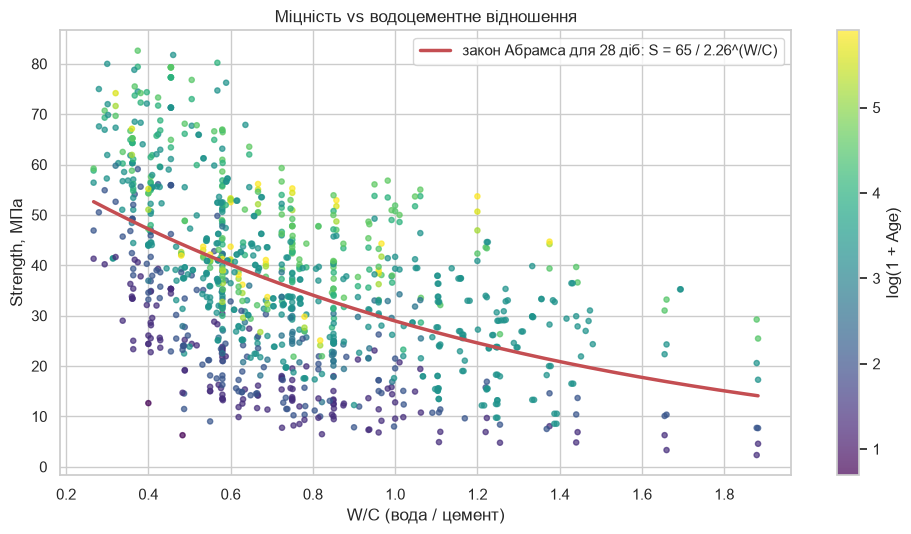

Pearson r з міцністю: W/C = -0.501, Water = -0.290, Cement = 0.498


In [13]:
wc = df['Water'] / df['Cement']
is28 = df['Age'] == 28
slope, intercept = np.polyfit(wc[is28], np.log(df.loc[is28, TARGET]), 1)   # ln S = ln A - (W/C)·ln B
A, B = np.exp(intercept), np.exp(-slope)

fig, ax = plt.subplots(figsize=(10, 5.5))
sc = ax.scatter(wc, df[TARGET], c=np.log1p(df['Age']), cmap='viridis', s=14, alpha=0.7)
wc_grid = np.linspace(wc.min(), wc.max(), 200)
ax.plot(wc_grid, A / B ** wc_grid, 'r-', lw=2.5, label=f'закон Абрамса для 28 діб: S = {A:.0f} / {B:.2f}^(W/C)')
plt.colorbar(sc, ax=ax).set_label('log(1 + Age)')
ax.set(xlabel='W/C (вода / цемент)', ylabel='Strength, МПа', title='Міцність vs водоцементне відношення')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pearson r з міцністю: W/C = {np.corrcoef(wc, df[TARGET])[0, 1]:.3f}, "
      f"Water = {df['Water'].corr(df[TARGET]):.3f}, Cement = {df['Cement'].corr(df[TARGET]):.3f}")

W/C корелює з міцністю сильніше (|r| ≈ 0.50), ніж вода окремо (0.29). Зв'язок нелінійний і добре описується законом Абрамса. Тому `WC = Water / Cement` можна додати як ознаку (перевірка в розділі 7). Нової інформації для нейромережі вона не дає, бо обидві складові вже є серед входів, але готове відношення може спростити навчання на малій вибірці.

### 3.9 Висновки EDA
1. 1030 рядків × 9 числових колонок, пропусків і категоріальних ознак немає.
2. Є 25 повних дублікатів (2.4 %), їх я обробляю в розділі 4. Крім того, однакові суміші мають повторні випробування з різною міцністю, тобто в даних є шум 1-8 МПа (медіана ≈ 3 МПа), який модель не усуне.
3. Масштаби ознак різні, тому потрібен StandardScaler.
4. На око найважливіші фактори такі: цемент, вік, вода (W/C), суперпластифікатор. Зв'язки нелінійні (за віком логарифмічний, за суперпластифікатором з насиченням), і фактори взаємодіють між собою. Для такої задачі підходить нейромережа з нелінійними активаціями.
5. `Age` дискретний і скошений, тому для нього підходить перетворення `log1p`.

## 4. Підготовка даних

### 4.1 Дублікати

Я видаляю 25 повних дублікатів, у яких однакові всі 8 ознак і міцність.
- Найімовірніше, це той самий результат випробування, внесений у таблицю двічі. Нової інформації такі рядки не додають.
- Якщо їх залишити, одна копія може потрапити в train, а друга в test. Тоді модель уже «бачила» відповідь, і тестова оцінка буде завищеною через витік даних.
- Рядки з однаковим складом і віком, але різною міцністю є реальними повторними вимірюваннями (шумом), тому їх я залишаю.

In [14]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f'{len(df)} → {len(df_clean)} рядків (видалено {len(df) - len(df_clean)} повних дублікатів)')

1030 → 1005 рядків (видалено 25 повних дублікатів)


### 4.2 Категоріальні ознаки та інженерія ознак

- Умова згадує кодування категоріальних ознак, але тут воно не потрібне: усі 8 предикторів числові й за змістом неперервні. `Age` має 14 дискретних значень, проте це впорядкована кількісна величина. One-hot кодування втратило б інформацію про порядок віків і відстань між ними.
- Я додаю дві інженерні ознаки, їхню користь перевіряю на валідації в розділі 7:
  - `LogAge = log1p(Age)` лінеаризує логарифмічний ріст міцності й зменшує асиметрію;
  - `WC = Water / Cement` є водоцементним відношенням (закон Абрамса). `Cement ≥ 102`, тож ділення безпечне.
- З них складаю три набори ознак: `raw` (8 вихідних), `log_age` (Age → LogAge) і `log_age_wc` (+ WC).

In [15]:
def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Add engineered features; works on any frame with the 8 raw columns."""
    out = frame.copy()
    out['LogAge'] = np.log1p(out['Age'])          # log-like hydration kinetics, reduces skew
    out['WC'] = out['Water'] / out['Cement']      # water-cement ratio (Abrams' law)
    return out


data = add_features(df_clean)

NO_AGE = [f for f in BASE_FEATURES if f != 'Age']
FEATURE_SETS = {
    'raw': BASE_FEATURES,                        # 8 original predictors
    'log_age': NO_AGE + ['LogAge'],              # Age -> log1p(Age)
    'log_age_wc': NO_AGE + ['LogAge', 'WC'],     # + water-cement ratio
}
for name, cols in FEATURE_SETS.items():
    print(f'{name:11s} ({len(cols)}): {cols}')

raw         (8): ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age']
log_age     (8): ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'LogAge']
log_age_wc  (9): ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'LogAge', 'WC']


### 4.3 X / y та розбиття train / validation / test (70 / 15 / 15)

- y = `Strength` (МПа), X = обраний набір ознак.
- Вибірок три: train (70 %) для навчання, validation (15 %) для ранньої зупинки та вибору гіперпараметрів, test (15 %) для однієї фінальної незалежної оцінки. Звичайного розбиття train/test з інструкції тут мало, бо тоді тест служив би і для вибору, і для оцінки.
- Розбиття стратифіковане за квінтилями міцності, щоб на малій вибірці розподіл цілі в усіх частинах був схожим. Для відтворюваності `random_state = 42`.

In [16]:
y_all = data[TARGET].to_numpy(dtype=np.float32)
strength_bins = pd.qcut(y_all, q=5, labels=False)              # quintiles -> stratified split for regression
idx_all = np.arange(len(data))

idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, random_state=SEED, stratify=strength_bins)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=SEED,
                                     stratify=strength_bins[idx_tmp])
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

split_summary = pd.DataFrame({
    name: pd.Series(y).describe()[['count', 'mean', 'std', 'min', 'max']]
    for name, y in [('train', y_train), ('validation', y_val), ('test', y_test)]
}).T
split_summary['частка'] = split_summary['count'] / len(data)
split_summary

,count,mean,std,min,max,частка
train,703.000,35.208,16.142,2.330,81.750,0.700
validation,151.000,35.376,17.150,3.320,82.600,0.150
test,151.000,35.321,16.167,6.810,79.990,0.150


### 4.4 Нормалізація: `StandardScaler`, навчений лише на train

Стандартизація $z = (x - \mu_{train}) / \sigma_{train}$ зводить ознаки до спільного масштабу. Без неї ознаки зі значеннями ~1000 (заповнювачі) домінували б у градієнтах, і ReLU-мережа вчилася б повільно й нестабільно. Середнє та σ рахуються тільки на train, а до validation і test застосовується той самий `transform`. Інакше статистики тесту потрапили б у навчання (data leakage).

Ціль я не масштабую. Її діапазон помірний (2-83 МПа), а в одиницях МПа loss (MSE, МПа²) можна напряму порівнювати з орієнтирами з умови. Натомість зміщення (bias) вихідного нейрона ініціалізую середнім `y_train` (див. розділ 5).

In [17]:
def prepare_xy(feature_set: str, split=None):
    """Select a feature set, fit StandardScaler on TRAIN only, transform train/val/test."""
    i_tr, i_va, i_te = split if split is not None else (idx_train, idx_val, idx_test)
    X = data[FEATURE_SETS[feature_set]].to_numpy(dtype=np.float32)
    scaler = StandardScaler().fit(X[i_tr])                      # statistics from train only -> no leakage
    X_tr, X_va, X_te = (scaler.transform(X[i]).astype(np.float32) for i in (i_tr, i_va, i_te))
    return X_tr, X_va, X_te, scaler


X_tr_raw, X_va_raw, X_te_raw, scaler_raw = prepare_xy('raw')
pd.DataFrame({
    'μ (train, до)': scaler_raw.mean_, 'σ (train, до)': scaler_raw.scale_,
    'mean train': X_tr_raw.mean(0), 'std train': X_tr_raw.std(0),
    'mean val': X_va_raw.mean(0), 'std val': X_va_raw.std(0),
}, index=FEATURE_SETS['raw'])

,"μ (train, до)","σ (train, до)",mean train,std train,mean val,std val
Cement,276.300,102.927,-0.000,1.000,0.097,1.072
Slag,71.429,86.408,0.000,1.000,0.090,1.032
FlyAsh,57.333,64.415,-0.000,1.000,-0.127,0.983
Water,181.322,21.646,0.000,1.000,0.197,0.928
Superplasticizer,6.226,6.009,-0.000,1.000,-0.090,0.926
CoarseAggregate,974.914,78.144,-0.000,1.000,-0.099,0.985
FineAggregate,775.487,79.114,-0.000,1.000,-0.177,1.072
Age,45.640,63.621,-0.000,1.000,-0.018,0.941


Після стандартизації ознаки train мають середнє 0 і σ = 1. На validation значення близькі до 0 і 1, але не точно такі, бо використано статистики train. Так і має бути.

### 4.5 `Dataset` і `DataLoader`

Для міні-батчів я написав власний клас `Dataset` (з обов'язковими `__len__` і `__getitem__`) і використовую `DataLoader`. Train-завантажувач перемішує дані кожну епоху (`shuffle=True` з фіксованим генератором, тому результат відтворюваний). `num_workers=0`, бо в Jupyter на macOS/Windows паралельні воркери можуть зависати, а для 700 рядків вони й не потрібні.

In [18]:
class ConcreteDataset(Dataset):
    """Tabular dataset: standardized features -> compressive strength (MPa)."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)   # (N, 1) to match model output

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_loaders(X_tr, y_tr, X_va, y_va, batch_size=32, seed=SEED):
    g = torch.Generator().manual_seed(seed)                            # reproducible shuffling
    train_loader = DataLoader(ConcreteDataset(X_tr, y_tr), batch_size=batch_size,
                              shuffle=True, generator=g, num_workers=0)
    val_loader = DataLoader(ConcreteDataset(X_va, y_va), batch_size=256, shuffle=False, num_workers=0)
    return train_loader, val_loader


train_loader, val_loader = make_loaders(X_tr_raw, y_train, X_va_raw, y_val, batch_size=32)
xb, yb = next(iter(train_loader))
print(f'Батч: X {tuple(xb.shape)}, y {tuple(yb.shape)}; батчів на епоху: {len(train_loader)} '
      f'(train = {len(train_loader.dataset)} прикладів)')

Батч: X (32, 8), y (32, 1); батчів на епоху: 22 (train = 703 прикладів)


## 5. Модель: клас нейронної мережі на PyTorch

Архітектура: багатошаровий перцептрон (MLP) для регресії, `вхід (8 ознак) → Linear(64) → ReLU → Linear(32) → ReLU → Linear(1)`.

Чому саме так:
- Розмір вхідного шару дорівнює кількості ознак (8 для `raw`, 9 для `log_age_wc`) і задається параметром `in_dim`.
- Вихідний шар має 1 нейрон без активації (лінійний), бо міцність є неперервним дійсним числом. Sigmoid або softmax обмежили б діапазон.
- Два приховані шари 64 → 32 утворюють «звужувальну піраміду». Двох шарів досить, щоб апроксимувати нелінійні залежності та взаємодії, знайдені в EDA (вік × цемент, вода × суперпластифікатор). Мережа невелика (≈ 2.7 тис. параметрів), бо навчальних рядків лише ≈ 700. Велика глибока мережа (як 256→128→64 у лекції для BigMart) на таких даних легко перенавчилася б. Ширші, вужчі й глибші варіанти я порівнюю в розділі 7.
- ReLU є стандартною активацією прихованих шарів. Вона дешева й не насичується для x > 0, тому градієнт згасає рідше, ніж у sigmoid або tanh.
- Bias виходу ініціалізовано середнім `y_train`. Мережа стартує з прогнозу середнім (MSE ≈ 280), а не з ≈ 1500 при нульовому виході. Тому на перших кроках SGD немає вибухових градієнтів, і мережа вчить лише відхилення від середнього.
- Dropout опційний (за замовчуванням вимкнений), він потрібен для експериментів з регуляризацією.

Код написано в стилі курсу: клас успадковує `nn.Module`, шари зібрано в `nn.Sequential` (`self.features`), а `forward` викликає цю послідовність.

In [19]:
class ConcreteNet(nn.Module):
    """MLP regressor: in_dim -> [Linear -> ReLU (-> Dropout)] x len(hidden) -> Linear(1)."""

    def __init__(self, in_dim: int, hidden=(64, 32), dropout: float = 0.0, y_mean: float | None = None):
        super().__init__()
        layers, prev = [], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))              # linear output: strength is an unbounded real value
        self.features = nn.Sequential(*layers)
        if y_mean is not None:                          # start from the "predict the mean" baseline
            with torch.no_grad():
                self.features[-1].bias.fill_(y_mean)

    def forward(self, x):
        return self.features(x)


demo_model = ConcreteNet(in_dim=X_tr_raw.shape[1], hidden=(64, 32), y_mean=float(y_train.mean()))
print(demo_model)
n_params = sum(p.numel() for p in demo_model.parameters())
print(f'\nПараметрів: {n_params:,}; навчальних прикладів: {len(y_train)}')
with torch.no_grad():
    print('Вихід на батчі:', tuple(demo_model(xb).shape), '| перші прогнози (до навчання):',
          demo_model(xb[:3]).ravel().numpy().round(2))

ConcreteNet(
  (features): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

Параметрів: 2,689; навчальних прикладів: 703
Вихід на батчі: (32, 1) | перші прогнози (до навчання): [35.03 35.06 35.18]


## 6. Налаштування та навчання моделі

### 6.1 Функція втрат, оптимізатор, гіперпараметри

Як функцію втрат я взяв `nn.MSELoss` (середньоквадратична помилка). Причини такі:
- Задача є регресією неперервної величини, і MSE для неї стандартний вибір: мінімізація MSE дає оцінку максимальної правдоподібності, якщо шум вимірювань гаусовий.
- Помилка підноситься до квадрата, тому великі промахи штрафуються сильніше. Для міцності конструкції одна помилка в 15 МПа значно небезпечніша, ніж три по 5 МПа.
- MSE гладка й диференційовна всюди, тому градієнти стабільні. У MAE (`L1Loss`) градієнт сталий за модулем, і вона гірше «доводить» мінімум.
- MSE збігається з головною метрикою умови, тож модель оптимізує саме те, за чим її оцінюють.

Оптимізатор для базової моделі: SGD (`lr = 0.01`, без momentum), як пропонує інструкція. Він простий і прозорий. Далі я порівнюю його з Adam (`lr = 1e-3`), який підбирає крок для кожного параметра окремо і зазвичай збігається швидше й стабільніше. Ширша сітка (SGD з momentum, різні lr) є в розділі 7.

| Гіперпараметр | Значення | Обґрунтування |
|---|---|---|
| `batch_size` | 32 | ≈ 22 оновлення ваг за епоху на ≈ 700 рядках; шум міні-батчів працює як легка регуляризація; стандартне значення |
| `lr` (SGD) | 0.01 | класичне стартове значення (як у лекції); більші кроки з momentum розбігаються (див. розділ 7) |
| `lr` (Adam) | 1e-3 | значення за замовчуванням, рекомендоване для Adam |
| `max_epochs` | 1000 | верхня межа, фактичну кількість епох визначає рання зупинка |
| `patience` | 100 | зупинка, якщо val MSE не покращився 100 епох; зберігаються ваги, найкращі на val (`state_dict`) |

### 6.2 Цикл навчання

Одна епоха означає прохід усіма міні-батчами train: `forward → loss → zero_grad → backward → step`. Після кожної епохи модель оцінюється на validation у режимі `model.eval()` + `torch.no_grad()`. Train-loss епохи рахується як середнє по всіх прикладах (зважене за розміром батчу), а не як loss останнього батчу.

In [20]:
def evaluate_loss(model, loader, criterion) -> float:
    """Average loss over a whole loader (per-sample weighted)."""
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total += criterion(model(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n


def train_model(model, train_loader, val_loader, optimizer, criterion,
                max_epochs=1000, patience=100, log_every=0) -> dict:
    """Mini-batch training with per-epoch logging and early stopping on validation loss."""
    history = {'train_loss': [], 'val_loss': []}
    best_val, best_epoch = float('inf'), 0
    best_state = copy.deepcopy(model.state_dict())
    stop_reason = f'досягнуто max_epochs = {max_epochs}'

    for epoch in range(1, max_epochs + 1):
        model.train()
        running, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)        # forward pass + loss
            loss.backward()                         # backpropagation
            optimizer.step()                        # weight update
            running += loss.item() * len(xb)
            seen += len(xb)
        train_loss = running / seen                 # epoch average over all samples
        val_loss = evaluate_loss(model, val_loader, criterion)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if not np.isfinite(val_loss):               # lr too large -> divergence
            stop_reason = f'розбіжність (loss = {val_loss}) на епосі {epoch}'
            break
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:
            stop_reason = f'рання зупинка на епосі {epoch} (val MSE не покращувався {patience} епох)'
            break
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print(f'epoch {epoch:4d} | train MSE {train_loss:8.2f} | val MSE {val_loss:8.2f} '
                  f'| val RMSE {np.sqrt(val_loss):5.2f} МПа')

    model.load_state_dict(best_state)               # keep the best-on-validation weights
    history.update(best_epoch=best_epoch, best_val=best_val, stop_reason=stop_reason)
    if log_every:
        print(f'→ {stop_reason}; найкраща епоха {best_epoch}, val MSE = {best_val:.2f}')
    return history


def predict(model, X: np.ndarray) -> np.ndarray:
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy().ravel()


def regression_metrics(y_true, y_pred) -> dict:
    return {'MSE': mean_squared_error(y_true, y_pred), 'RMSE': root_mean_squared_error(y_true, y_pred),
            'MAE': mean_absolute_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}

In [21]:
_RUN_CACHE = {}   # identical configs (incl. seed) are deterministic -> reuse instead of retraining


def run_experiment(feature_set='raw', hidden=(64, 32), optimizer='sgd', lr=0.01, momentum=0.0,
                   weight_decay=0.0, dropout=0.0, batch_size=32, max_epochs=1000, patience=100,
                   seed=SEED, split=None, log_every=0) -> dict:
    """Build data + model for a config, train with early stopping, return model and validation metrics."""
    cfg = dict(feature_set=feature_set, hidden=tuple(hidden), optimizer=optimizer, lr=lr,
               momentum=momentum if optimizer == 'sgd' else 0.0, weight_decay=weight_decay,
               dropout=dropout, batch_size=batch_size, seed=seed)
    key = tuple(cfg.items())
    if split is None and not log_every and key in _RUN_CACHE:
        return _RUN_CACHE[key]

    i_tr, i_va, i_te = split if split is not None else (idx_train, idx_val, idx_test)
    X_tr, X_va, X_te, scaler = prepare_xy(feature_set, (i_tr, i_va, i_te))
    y_tr, y_va = y_all[i_tr], y_all[i_va]

    set_seed(seed)
    tr_loader, va_loader = make_loaders(X_tr, y_tr, X_va, y_va, batch_size, seed)
    model = ConcreteNet(X_tr.shape[1], hidden, dropout, y_mean=float(y_tr.mean())).to(DEVICE)
    if optimizer == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    t0 = time.time()
    history = train_model(model, tr_loader, va_loader, opt, nn.MSELoss(), max_epochs, patience, log_every)
    result = {'cfg': cfg, 'model': model, 'scaler': scaler, 'history': history,
              'X': {'train': X_tr, 'val': X_va, 'test': X_te},
              'val': regression_metrics(y_va, predict(model, X_va)), 'time': time.time() - t0}
    if split is None:
        _RUN_CACHE[key] = result
    return result


def describe(cfg: dict) -> str:
    opt = f"SGD(m={cfg['momentum']})" if cfg['optimizer'] == 'sgd' else 'Adam'
    return (f"{opt} lr={cfg['lr']:g} | {'-'.join(map(str, cfg['hidden']))} | do={cfg['dropout']} "
            f"| wd={cfg['weight_decay']:g} | {cfg['feature_set']}")


def summary_row(res: dict, name: str | None = None) -> dict:
    h = res['history']
    return {'модель': name or describe(res['cfg']), 'епох': len(h['train_loss']),
            'найкр. епоха': h['best_epoch'], 'val MSE': res['val']['MSE'], 'val RMSE': res['val']['RMSE'],
            'val MAE': res['val']['MAE'], 'val R²': res['val']['R2'], 'час, с': res['time']}

### 6.3 Модель №1: SGD (lr = 0.01), вихідні 8 ознак

In [22]:
res_sgd = run_experiment(feature_set='raw', hidden=(64, 32), optimizer='sgd', lr=0.01, log_every=50)

epoch    1 | train MSE   185.80 | val MSE   123.07 | val RMSE 11.09 МПа


epoch   50 | train MSE    23.34 | val MSE    43.28 | val RMSE  6.58 МПа


epoch  100 | train MSE    13.41 | val MSE    33.21 | val RMSE  5.76 МПа


epoch  150 | train MSE     8.65 | val MSE    36.25 | val RMSE  6.02 МПа


→ рання зупинка на епосі 195 (val MSE не покращувався 100 епох); найкраща епоха 95, val MSE = 30.13


### 6.4 Модель №2: Adam (lr = 1e-3), ті самі ознаки й архітектура

In [23]:
res_adam = run_experiment(feature_set='raw', hidden=(64, 32), optimizer='adam', lr=1e-3, log_every=100)

epoch    1 | train MSE   257.41 | val MSE   284.76 | val RMSE 16.87 МПа


epoch  100 | train MSE    23.61 | val MSE    42.74 | val RMSE  6.54 МПа


epoch  200 | train MSE    17.13 | val MSE    36.94 | val RMSE  6.08 МПа


epoch  300 | train MSE    13.71 | val MSE    33.94 | val RMSE  5.83 МПа


epoch  400 | train MSE    11.29 | val MSE    32.50 | val RMSE  5.70 МПа


epoch  500 | train MSE     9.63 | val MSE    29.97 | val RMSE  5.47 МПа


epoch  600 | train MSE     8.66 | val MSE    29.75 | val RMSE  5.45 МПа


→ рання зупинка на епосі 643 (val MSE не покращувався 100 епох); найкраща епоха 543, val MSE = 28.68


### 6.5 Криві навчання та порівняння на validation

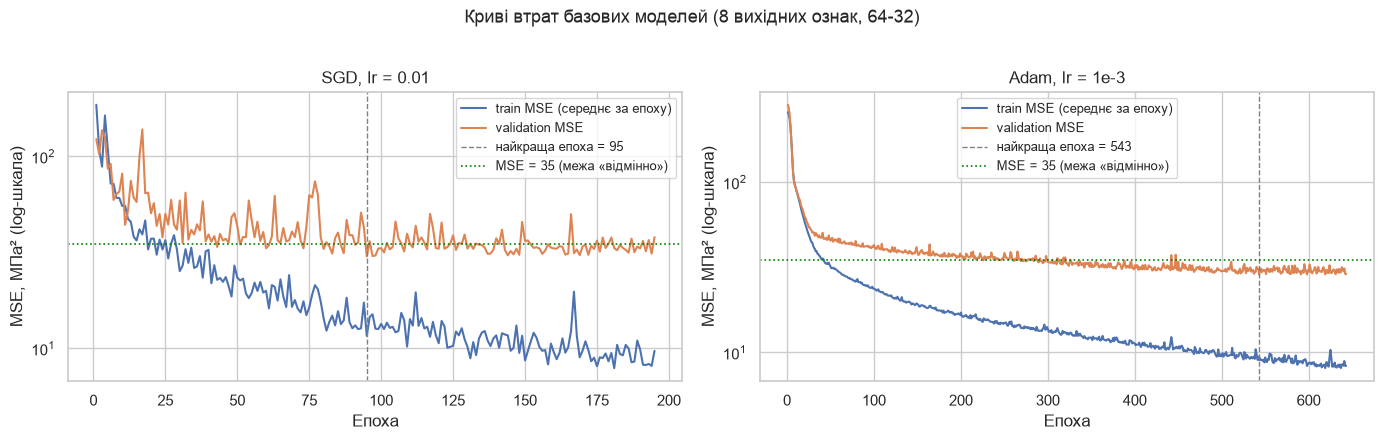

,модель,епох,найкр. епоха,val MSE,val RMSE,val MAE,val R²,"час, с"
0,SGD lr=0.01 | 64-32 | raw,195,95,30.130,5.489,3.898,0.897,1.077
1,Adam lr=1e-3 | 64-32 | raw,643,543,28.676,5.355,3.757,0.902,4.867


In [24]:
def plot_history(histories: dict, suptitle: str = '') -> None:
    fig, axes = plt.subplots(1, len(histories), figsize=(7 * len(histories), 4.3), squeeze=False)
    for ax, (name, h) in zip(axes[0], histories.items()):
        epochs = np.arange(1, len(h['train_loss']) + 1)
        ax.plot(epochs, h['train_loss'], label='train MSE (середнє за епоху)')
        ax.plot(epochs, h['val_loss'], label='validation MSE')
        ax.axvline(h['best_epoch'], color='grey', ls='--', lw=1, label=f"найкраща епоха = {h['best_epoch']}")
        ax.axhline(35, color='green', ls=':', lw=1.2, label='MSE = 35 (межа «відмінно»)')
        ax.set_yscale('log')
        ax.set(xlabel='Епоха', ylabel='MSE, МПа² (log-шкала)', title=name)
        ax.legend(fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


plot_history({'SGD, lr = 0.01': res_sgd['history'], 'Adam, lr = 1e-3': res_adam['history']},
             'Криві втрат базових моделей (8 вихідних ознак, 64-32)')
pd.DataFrame([summary_row(res_sgd, 'SGD lr=0.01 | 64-32 | raw'),
              summary_row(res_adam, 'Adam lr=1e-3 | 64-32 | raw')])

Висновки щодо базових моделей:
- Обидві мережі навчаються. Val MSE падає з рівня константного прогнозу (≈ 120-280 МПа² на першій епосі) до ≈ 30 МПа², тож уже перша модель на валідації потрапляє в зону «відмінно» (R² ≈ 0.90).
- SGD (lr = 0.01) збігається швидко (найкраща епоха 95), але крива val дуже «шумна». Крок однаковий для всіх параметрів, а градієнти на батчах по 32 приклади сильно різняться. Після ≈ 100-ї епохи train MSE далі падає (13 → 9), а val MSE тримається на рівні ≈ 33-36. Тут починається перенавчання, і рання зупинка повертає ваги 95-ї епохи (val MSE 30.1).
- Adam (lr = 1e-3) сходиться плавніше й трохи краще (val MSE 28.7 проти 30.1), але повільно (найкраща епоха 543): з таким малим кроком мережа довго «доучується».
- Розрив між train ≈ 9 і val ≈ 29-30 МПа² вказує на помірне перенавчання: 2.7 тис. параметрів на 703 прикладах дозволяють мережі частково запам'ятати шум. Тому рання зупинка за validation обов'язкова. У розділі 7 я пробую інші ознаки, lr, архітектури й регуляризацію.

## 7. Оптимізація: експерименти з ознаками, архітектурою та гіперпараметрами (бонус)

Усі порівняння в цьому розділі зроблено лише за validation, test не використовується. Порядок такий: (A) набір ознак, (B) сітка «архітектура × оптимізатор × lr», (C) регуляризація, (D) перевірка стабільності найкращих конфігурацій на кількох seed.

### 7.A Вплив інженерних ознак (`log1p(Age)`, `W/C`)

Я фіксую Adam, lr = 1e-3, 64-32 і змінюю лише набір ознак. Кожну конфігурацію навчаю з двома seed, щоб відрізнити ефект від випадковості.

In [25]:
EXP_START = time.time()
rows = []
for fs in FEATURE_SETS:
    for seed in (42, 7):
        r = run_experiment(feature_set=fs, hidden=(64, 32), optimizer='adam', lr=1e-3, seed=seed)
        rows.append({'набір ознак': fs, 'seed': seed, **{f'val {k}': v for k, v in r['val'].items()},
                     'найкр. епоха': r['history']['best_epoch']})
exp_a_runs = pd.DataFrame(rows)
exp_a = (exp_a_runs.groupby('набір ознак', sort=False)
         .agg(**{'val MSE (сер.)': ('val MSE', 'mean'), 'val RMSE (сер.)': ('val RMSE', 'mean'),
                 'val RMSE (σ між seed)': ('val RMSE', 'std'), 'val MAE (сер.)': ('val MAE', 'mean'),
                 'val R² (сер.)': ('val R2', 'mean')})
         .sort_values('val MSE (сер.)'))
BEST_FS = exp_a.index[0]
print('Найкращий набір ознак за val MSE:', BEST_FS)
exp_a

Найкращий набір ознак за val MSE: log_age


,val MSE (сер.),val RMSE (сер.),val RMSE (σ між seed),val MAE (сер.),val R² (сер.)
набір ознак,,,,,
log_age,24.748,4.975,0.035,3.399,0.915
log_age_wc,26.034,5.101,0.189,3.525,0.911
raw,29.290,5.412,0.080,3.827,0.900


- Найбільший виграш дає `log1p(Age)`: середній val MSE 29.3 → 24.7 (−16 %), R² 0.900 → 0.915. Розкид між seed малий (σ RMSE 0.04-0.08 МПа), тож ефект не випадковий. Логарифм лінеаризує криву набору міцності (див. 3.5), і мережі не треба витрачати нейрони на апроксимацію «зламу» біля 28 діб. Крім того, рідкісні зразки віком 180-365 діб після стандартизації перестають бути викидами.
- Додавання `W/C` не допомогло (26.0 проти 24.7). `Water` і `Cement` уже є на вході, і мережа може сама побудувати їхню нелінійну комбінацію. Ще одна сильно корельована ознака на 703 прикладах лише додає ступенів свободи для перенавчання. Для лінійних моделей та інтерпретації (закон Абрамса) W/C лишається корисним.
- Далі я використовую набір `log_age`.

### 7.B Сітка: архітектура × оптимізатор × learning rate

На найкращому наборі ознак перебираю 3 архітектури (`32`, `64-32`, `128-64-32`) × 2 оптимізатори (SGD з momentum = 0.9, Adam) × 3 значення lr (1e-3, 3e-3, 1e-2), разом 18 запусків.

In [26]:
GRID_HIDDEN = [(32,), (64, 32), (128, 64, 32)]
GRID_OPT = [('sgd', 0.9), ('adam', 0.0)]
GRID_LR = [1e-3, 3e-3, 1e-2]

grid_results = []
for hidden in GRID_HIDDEN:
    for opt_name, momentum in GRID_OPT:
        for lr in GRID_LR:
            grid_results.append(run_experiment(feature_set=BEST_FS, hidden=hidden, optimizer=opt_name,
                                               lr=lr, momentum=momentum))

exp_b = pd.DataFrame([summary_row(r) for r in grid_results]).sort_values('val MSE').reset_index(drop=True)
exp_b

,модель,епох,найкр. епоха,val MSE,val RMSE,val MAE,val R²,"час, с"
0,Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age,237,137,18.653,4.319,2.968,0.936,2.160
1,SGD(m=0.9) lr=0.003 | 64-32 | do=0.0 | wd=0 | ...,274,174,21.130,4.597,3.241,0.928,1.981
2,Adam lr=0.003 | 64-32 | do=0.0 | wd=0 | log_age,742,642,21.178,4.602,3.124,0.928,6.673
3,SGD(m=0.9) lr=0.001 | 128-64-32 | do=0.0 | wd=...,227,127,21.751,4.664,2.997,0.926,1.605
4,SGD(m=0.9) lr=0.001 | 64-32 | do=0.0 | wd=0 | ...,290,190,21.776,4.666,3.128,0.925,1.772
5,SGD(m=0.9) lr=0.001 | 32 | do=0.0 | wd=0 | log...,274,174,24.194,4.919,3.438,0.917,1.396
6,Adam lr=0.001 | 64-32 | do=0.0 | wd=0 | log_age,475,375,24.500,4.950,3.394,0.916,4.410
7,Adam lr=0.003 | 128-64-32 | do=0.0 | wd=0 | lo...,253,153,24.710,4.971,3.168,0.915,2.689
8,Adam lr=0.01 | 128-64-32 | do=0.0 | wd=0 | log...,191,91,25.234,5.023,3.426,0.914,1.839
9,SGD(m=0.9) lr=0.003 | 32 | do=0.0 | wd=0 | log...,325,225,25.733,5.073,3.660,0.912,1.523


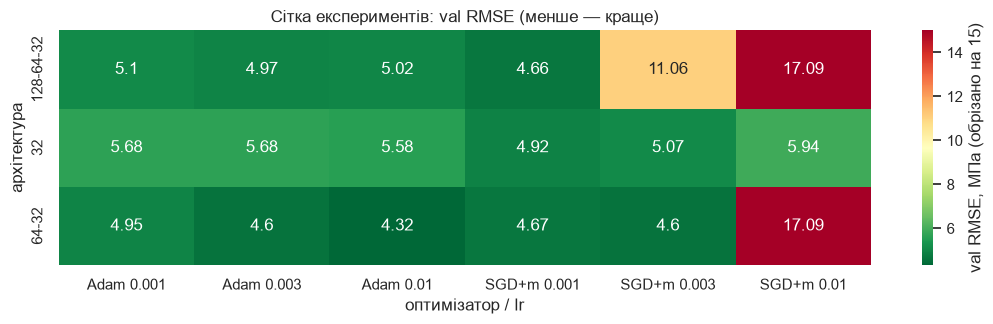

Найкраща конфігурація сітки: Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age


In [27]:
pivot = pd.DataFrame([{'архітектура': '-'.join(map(str, r['cfg']['hidden'])),
                       'оптимізатор / lr': f"{'SGD+m' if r['cfg']['optimizer'] == 'sgd' else 'Adam'} {r['cfg']['lr']:g}",
                       'val RMSE': r['val']['RMSE']} for r in grid_results]
                     ).pivot(index='архітектура', columns='оптимізатор / lr', values='val RMSE')
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(pivot.clip(upper=15), annot=pivot.round(2), fmt='', cmap='RdYlGn_r', ax=ax,
            cbar_kws={'label': 'val RMSE, МПа (обрізано на 15)'})
ax.set_title('Сітка експериментів: val RMSE (менше — краще)')
plt.tight_layout()
plt.show()

best_b = min(grid_results, key=lambda r: r['val']['MSE'])
print('Найкраща конфігурація сітки:', describe(best_b['cfg']))

- Найкраща комбінація: Adam, lr = 0.01, 64-32 (val RMSE 4.32 МПа, R² 0.936). З lr = 1e-3 Adam сходиться повільно і до гіршого рішення (4.95 МПа). Більший крок, імовірно, ще й працює як неявна регуляризація (шумніший спуск знаходить «пологіші» мінімуми), а від перенавчання захищає рання зупинка.
- SGD з momentum дуже чутливий до lr. При 1e-3…3e-3 він не гірший за Adam (4.6-4.7 МПа для 64-32), але при lr = 0.01 навчання ламається. Для 64-32 val MSE ≈ 292, тобто дорівнює дисперсії цілі (R² = 0): завеликі кроки «вбили» ReLU-нейрони (*dying ReLU*), і мережа видає константу. Для 128-64-32 loss став NaN уже на 1-й епосі, а при lr = 3e-3 навчання теж нестабільне (R² 0.58). Adam з адаптивним кроком стабільний при всіх трьох lr.
- Щодо архітектури: один шар `32` (≈ 300 параметрів) у більшості комбінацій гірший (4.9-5.9 МПа), бо йому бракує ємності для взаємодій факторів. `64-32` (≈ 2.7 тис.) найкращий. Глибший `128-64-32` (≈ 11.5 тис.) виграшу не дає і раніше перенавчається (найкращі епохи ≈ 90-150), для 703 прикладів він завеликий.
- Отже, оптимально мати два приховані шари помірної ширини. Правильний lr важливіший за вибір оптимізатора, але Adam значно надійніший.

### 7.C Регуляризація: Dropout і weight decay

Для найкращої конфігурації з сітки я пробую Dropout 0.1 та L2-регуляризацію (`weight_decay = 1e-4`), окремо й разом.

In [28]:
base_cfg = {k: best_b['cfg'][k] for k in ('feature_set', 'hidden', 'optimizer', 'lr', 'momentum')}
reg_results = [run_experiment(**base_cfg, dropout=do, weight_decay=wd)
               for do, wd in [(0.0, 0.0), (0.1, 0.0), (0.0, 1e-4), (0.1, 1e-4)]]
exp_c = pd.DataFrame([summary_row(r) for r in reg_results]).sort_values('val MSE').reset_index(drop=True)
exp_c

,модель,епох,найкр. епоха,val MSE,val RMSE,val MAE,val R²,"час, с"
0,Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age,237,137,18.653,4.319,2.968,0.936,2.160
1,Adam lr=0.01 | 64-32 | do=0.0 | wd=0.0001 | lo...,197,97,20.067,4.480,3.174,0.931,1.498
2,Adam lr=0.01 | 64-32 | do=0.1 | wd=0.0001 | lo...,226,126,25.722,5.072,3.589,0.912,1.858
3,Adam lr=0.01 | 64-32 | do=0.1 | wd=0 | log_age,226,126,27.840,5.276,3.656,0.905,2.363


Регуляризація не допомогла. Dropout 0.1 помітно погіршив val MSE (18.7 → 27.8), weight decay 1e-4 погіршив трохи (→ 20.1), обидва разом дали 25.7. Мережа й так невелика, а рання зупинка за validation сама добре регуляризує. Dropout у маленькій мережі на табличних даних вимикає помітну частку з 64/32 нейронів і додає шуму, тож модель недонавчається. Різниця 18.7 vs 20.1 на одному seed може бути випадковою, тому варіант з weight decay я перевіряю ще раз у 7.D.

### 7.D Стабільність: топ-3 конфігурації × 3 seed і вибір фінальної моделі

На 151 прикладі validation різниця в 1-2 МПа² між окремими запусками може виникати просто через випадкову ініціалізацію. Тому три найкращі різні конфігурації з A-C я перенавчаю з seed = 42, 7, 2024 і обираю ту, що має найменший середній val MSE. Фінальна модель усереднює прогнози трьох мереж цієї конфігурації (ансамбль). Усереднення зменшує дисперсію, пов'язану з випадковою ініціалізацією, і нічого не «підглядає» в тесті.

In [29]:
class EnsembleNet(nn.Module):
    """Averages predictions of several ConcreteNet models (same config, different seeds)."""

    def __init__(self, members):
        super().__init__()
        self.members = nn.ModuleList(members)

    def forward(self, x):
        return torch.stack([m(x) for m in self.members]).mean(dim=0)


SEEDS = (42, 7, 2024)
all_single = [r for r in _RUN_CACHE.values() if r['cfg']['seed'] == SEED]
top3, seen_cfgs = [], set()
for r in sorted(all_single, key=lambda r: r['val']['MSE']):
    cfg_no_seed = tuple((k, v) for k, v in r['cfg'].items() if k != 'seed')
    if cfg_no_seed not in seen_cfgs:
        seen_cfgs.add(cfg_no_seed)
        top3.append({k: v for k, v in r['cfg'].items() if k != 'seed'})
    if len(top3) == 3:
        break

rows, seed_runs = [], {}
for cfg in top3:
    runs = [run_experiment(**cfg, seed=s) for s in SEEDS]
    seed_runs[describe({**cfg, 'seed': None})] = runs
    ens = EnsembleNet([r['model'] for r in runs])
    ens_val = regression_metrics(y_val, predict(ens, runs[0]['X']['val']))
    rmses = [r['val']['RMSE'] for r in runs]
    rows.append({'конфігурація': describe({**cfg, 'seed': None}),
                 'val MSE (сер. 3 seed)': np.mean([r['val']['MSE'] for r in runs]),
                 'val RMSE (сер.)': np.mean(rmses), 'val RMSE (σ)': np.std(rmses),
                 'val R² (сер.)': np.mean([r['val']['R2'] for r in runs]),
                 'ансамбль: val MSE': ens_val['MSE'], 'ансамбль: val R²': ens_val['R2']})
exp_d = pd.DataFrame(rows).sort_values('val MSE (сер. 3 seed)').reset_index(drop=True)

FINAL_NAME = exp_d.loc[0, 'конфігурація']
final_runs = seed_runs[FINAL_NAME]
final_single = final_runs[0]                                  # seed = 42 member
final_model = EnsembleNet([r['model'] for r in final_runs])
FINAL_FS = final_single['cfg']['feature_set']
X_tr_f, X_va_f, X_te_f = (final_single['X'][k] for k in ('train', 'val', 'test'))
final_scaler = final_single['scaler']

print(f'Фінальна конфігурація: {FINAL_NAME}')
print(f'Час усіх експериментів розділу 7: {time.time() - EXP_START:.0f} с')
exp_d

Фінальна конфігурація: Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age
Час усіх експериментів розділу 7: 76 с


,конфігурація,val MSE (сер. 3 seed),val RMSE (сер.),val RMSE (σ),val R² (сер.),ансамбль: val MSE,ансамбль: val R²
0,Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age,19.846,4.453,0.124,0.932,17.988,0.938
1,Adam lr=0.01 | 64-32 | do=0.0 | wd=0.0001 | lo...,21.245,4.606,0.174,0.927,19.057,0.935
2,SGD(m=0.9) lr=0.003 | 64-32 | do=0.0 | wd=0 | ...,24.032,4.897,0.230,0.918,21.442,0.927


- Конфігурація Adam, lr = 0.01, 64-32, `log_age` лишається найкращою і на трьох seed: середній val MSE 19.8 (σ RMSE лише 0.12 МПа) проти 21.2 з weight decay і 24.0 у SGD + momentum.
- Ансамбль із трьох мереж знижує val MSE ще до 18.0 (R² 0.938). Окремі мережі помиляються по-різному, і усереднення частково ці помилки компенсує.
- Фінальна модель: ансамбль 3 × MLP `8 → 64 → ReLU → 32 → ReLU → 1`; ознаки `log_age` (7 компонентів + `log1p(Age)`), StandardScaler (train); Adam, lr = 0.01, batch 32, MSELoss, рання зупинка (patience 100). Усі експерименти розділу 7 займають ≈ 1 хв на CPU (≈ 30 навчань; однакові конфігурації не перенавчаються, а беруться з кешу).
- Validation використано для багатьох порівнянь, тому val-метрики фінальної моделі дещо оптимістичні. Незалежну оцінку дає тільки test (розділ 8).

## 8. Оцінка на тестовій вибірці

### 8.1 Вибір метрик

| Метрика | Формула | Чому використовуємо |
|---|---|---|
| MSE | $\frac{1}{n}\sum (y-\hat y)^2$ | та сама величина, що й функція втрат; сильно штрафує великі промахи; головна метрика з умови (МПа²) |
| RMSE | $\sqrt{MSE}$ | та сама інформація, але в МПа, тож її можна порівняти з σ цілі (≈ 16) і шумом повторних вимірювань (1-8, медіана ≈ 3) |
| MAE | $\frac{1}{n}\sum \lvert y-\hat y\rvert$ | «типова» помилка в МПа, стійка до поодиноких великих промахів; разом з RMSE показує, чи є рідкісні великі помилки (RMSE ≫ MAE) |
| R² | $1 - \frac{SS_{res}}{SS_{tot}}$ | частка поясненої дисперсії, не залежить від масштабу; 0 означає рівень прогнозу середнім, 1 означає ідеальну модель |

Для порівняння на тих самих train/test я оцінюю базові моделі: константний прогноз (середнє train), лінійну регресію, Random Forest і Gradient Boosting. Ансамблі дерев є сильним еталоном для табличних даних. Усі моделі навчені лише на train, а тест використовується один раз, у цій клітинці.

In [30]:
def rate(metric: str, value: float) -> str:
    """Map a test metric to the grading ranges from the assignment."""
    if metric == 'MSE':
        return 'відмінно' if value < 35 else 'добре' if value < 55 else 'непогано' if value <= 75 else 'нижче орієнтира'
    if metric == 'MAE':
        return 'відмінно' if value < 5 else 'добре' if value < 8 else 'непогано' if value <= 10 else 'нижче орієнтира'
    return 'відмінно' if value > 0.8 else 'добре' if value > 0.7 else 'непогано' if value >= 0.6 else 'нижче орієнтира'


X_raw_unscaled = data[BASE_FEATURES].to_numpy(dtype=np.float32)
X_tr_u, X_te_u = X_raw_unscaled[idx_train], X_raw_unscaled[idx_test]

reference = {
    'Константа (середнє train)': (DummyRegressor(strategy='mean'), X_tr_raw, X_te_raw),
    'Лінійна регресія (8 ознак)': (LinearRegression(), X_tr_raw, X_te_raw),
    f'Лінійна регресія ({FINAL_FS})': (LinearRegression(), X_tr_f, X_te_f),
    'Random Forest (300 дерев)': (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), X_tr_u, X_te_u),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                                                    subsample=0.8, random_state=SEED), X_tr_u, X_te_u),
}

test_rows, ref_test_pred = [], {}
for name, (est, X_fit, X_eval) in reference.items():
    est.fit(X_fit, y_train)
    ref_test_pred[name] = est.predict(X_eval)
    test_rows.append({'модель': name, **regression_metrics(y_test, ref_test_pred[name])})

nn_models = {
    'НМ №1: SGD lr=0.01, 64-32, raw': (res_sgd['model'], X_te_raw),
    'НМ №2: Adam lr=1e-3, 64-32, raw': (res_adam['model'], X_te_raw),
    f'НМ фінальна, 1 мережа (seed 42): {FINAL_NAME}': (final_single['model'], X_te_f),
    'НМ фінальна: ансамбль 3 seed': (final_model, X_te_f),
}
nn_test_pred = {}
for name, (model, X_eval) in nn_models.items():
    nn_test_pred[name] = predict(model, X_eval)
    test_rows.append({'модель': name, **regression_metrics(y_test, nn_test_pred[name])})

test_table = pd.DataFrame(test_rows).set_index('модель')
for m in ('MSE', 'MAE', 'R2'):
    test_table[f'оцінка {m}'] = [rate(m, v) for v in test_table[m]]
test_table

,MSE,RMSE,MAE,R2,оцінка MSE,оцінка MAE,оцінка R2
модель,,,,,,,
Константа (середнє train),259.656,16.114,12.964,-0.000,нижче орієнтира,нижче орієнтира,нижче орієнтира
Лінійна регресія (8 ознак),99.523,9.976,7.967,0.617,нижче орієнтира,добре,непогано
Лінійна регресія (log_age),56.168,7.495,5.826,0.784,непогано,добре,добре
Random Forest (300 дерев),25.836,5.083,3.530,0.900,відмінно,відмінно,відмінно
Gradient Boosting,20.866,4.568,2.951,0.920,відмінно,відмінно,відмінно
"НМ №1: SGD lr=0.01, 64-32, raw",33.498,5.788,3.907,0.871,відмінно,відмінно,відмінно
"НМ №2: Adam lr=1e-3, 64-32, raw",25.376,5.037,3.623,0.902,відмінно,відмінно,відмінно
"НМ фінальна, 1 мережа (seed 42): Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age",23.658,4.864,3.348,0.909,відмінно,відмінно,відмінно
НМ фінальна: ансамбль 3 seed,23.400,4.837,3.206,0.910,відмінно,відмінно,відмінно


In [31]:
y_pred_test = nn_test_pred['НМ фінальна: ансамбль 3 seed']
final_test = regression_metrics(y_test, y_pred_test)
final_val = regression_metrics(y_val, predict(final_model, X_va_f))
final_train = regression_metrics(y_train, predict(final_model, X_tr_f))

summary = pd.DataFrame({'train': final_train, 'validation': final_val, 'test': final_test}).T
print('Фінальна модель (ансамбль):', FINAL_NAME)
for m in ('MSE', 'MAE', 'R2'):
    print(f'  test {m:4s} = {final_test[m]:7.3f}  → «{rate(m, final_test[m])}» за шкалою умови')
summary

Фінальна модель (ансамбль): Adam lr=0.01 | 64-32 | do=0.0 | wd=0 | log_age
  test MSE  =  23.400  → «відмінно» за шкалою умови
  test MAE  =   3.206  → «відмінно» за шкалою умови
  test R2   =   0.910  → «відмінно» за шкалою умови


,MSE,RMSE,MAE,R2
train,4.034,2.008,1.349,0.984
validation,17.988,4.241,2.903,0.938
test,23.400,4.837,3.206,0.910


Наскільки точні ці числа? Тест містить лише 151 зразок, тому невизначеність метрик я оцінюю бутстрепом (2000 вибірок з поверненням із тестового набору). Також перевіряю, чи значуща різниця між нейромережею та Gradient Boosting (парний бутстреп, тобто ті самі вибірки для обох моделей).

In [32]:
rng = np.random.default_rng(SEED)
y_pred_gbm = ref_test_pred['Gradient Boosting']
boot_rows = []
for _ in range(2000):
    i = rng.integers(0, len(y_test), len(y_test))
    m = regression_metrics(y_test[i], y_pred_test[i])
    m['MSE(НМ) − MSE(GBM)'] = m['MSE'] - mean_squared_error(y_test[i], y_pred_gbm[i])
    boot_rows.append(m)
boot = pd.DataFrame(boot_rows)
boot_ci = pd.DataFrame({'точкова оцінка': [*final_test.values(), final_test['MSE'] - mean_squared_error(y_test, y_pred_gbm)],
                        '2.5 %': boot.quantile(0.025), '97.5 %': boot.quantile(0.975)})
print(f"Частка бутстреп-вибірок, де НМ точніша за GBM: {(boot['MSE(НМ) − MSE(GBM)'] < 0).mean():.1%}")
boot_ci

Частка бутстреп-вибірок, де НМ точніша за GBM: 24.4%


,точкова оцінка,2.5 %,97.5 %
MSE,23.400,14.866,34.346
RMSE,4.837,3.856,5.861
MAE,3.206,2.676,3.791
R2,0.910,0.868,0.942
MSE(НМ) − MSE(GBM),2.534,-4.101,9.952


Інтерпретація результатів на тесті:
- Фінальна модель має MSE ≈ 23.4 МПа², RMSE ≈ 4.8 МПа, MAE ≈ 3.2 МПа, R² ≈ 0.91. Усі три метрики умови потрапляють у зону **«відмінно»** (MSE < 35, MAE < 5, R² > 0.8). Типова помилка ≈ 3.2 МПа при середній міцності ≈ 35 МПа (≈ 9 %) і σ цілі ≈ 16 МПа. Модель пояснює ≈ 91 % дисперсії міцності.
- Бутстреп дає такі 95 % інтервали: для MSE ≈ 15-34 МПа², для R² ≈ 0.87-0.94, для MAE ≈ 2.7-3.8 МПа. Навіть песимістична межа лишається в зоні «відмінно». Водночас видно, що на 151 тестовому зразку оцінка точна лише до ± кількох МПа².
- RMSE (4.8) помітно більший за MAE (3.2). Більшість прогнозів дуже точні, але є кілька великих промахів (15-22 МПа), які MSE штрафує квадратично (розбір у 9.5).
- Test MSE (23.4) гірший за val (18.0), і це очікувано: validation використано для вибору конфігурації, тому її оцінка оптимістична. Train MSE ≈ 4 показує, що мережа частково запам'ятовує навчальні дані, а перенавчання стримує рання зупинка.
- Базові рівні: константа дає MSE ≈ 260, лінійна регресія 99.5 (8 ознак) і 56.2 (з `log1p(Age)`). Залежність суттєво нелінійна, і нейромережа зменшує MSE лінійної моделі в 2.4-4.3 раза. Оптимізація теж дала ефект: перша SGD-модель 33.5 → Adam 25.4 → фінальна 23.4 (−30 % MSE).
- Ансамблі дерев на малих табличних даних є сильним конкурентом. Random Forest (25.8) поступається мережі, Gradient Boosting (20.9) трохи точніший. Проте парний бутстреп показує, що різниця (≈ 2.5 МПа²) статистично незначуща: 95 % інтервал ≈ [−4; +10] МПа² містить нуль, і в ≈ 24 % вибірок мережа точніша. Як моделі поводяться на нових рецептурах, видно в 10.3.

## 9. Аналіз результатів

### 9.1 Криві навчання фінальної конфігурації

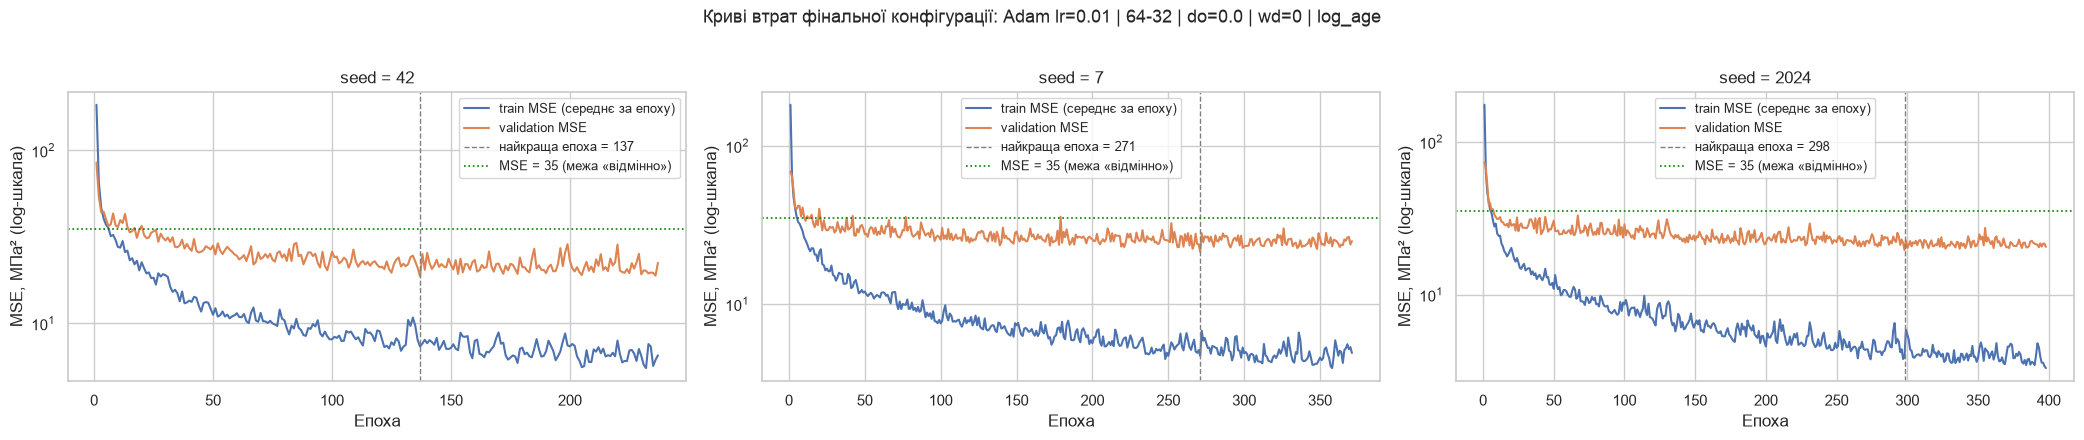

In [33]:
plot_history({f'seed = {r["cfg"]["seed"]}': r['history'] for r in final_runs},
             f'Криві втрат фінальної конфігурації: {FINAL_NAME}')

Для всіх трьох seed картина однакова. За перші ≈ 20 епох втрати різко падають (зі ≈ 180 до ≈ 30 МПа²), далі train MSE повільно спадає до ≈ 4-7, а val MSE виходить на плато ≈ 20-25 МПа² і коливається навколо нього. Найкращі епохи 137 / 271 / 298, після кожної з них минає 100 епох без покращення, і навчання зупиняється. Розрив між train і val зростає, що типово для перенавчання, і рання зупинка його «відсікає». Val loss при цьому не росте різко: після найкращої епохи модель просто перестає покращуватися на нових даних. Val MSE усіх seed опускається нижче межі «відмінно» (35) вже після ≈ 10-20 епох.

### 9.2 Фактичні vs прогнозовані значення (test)

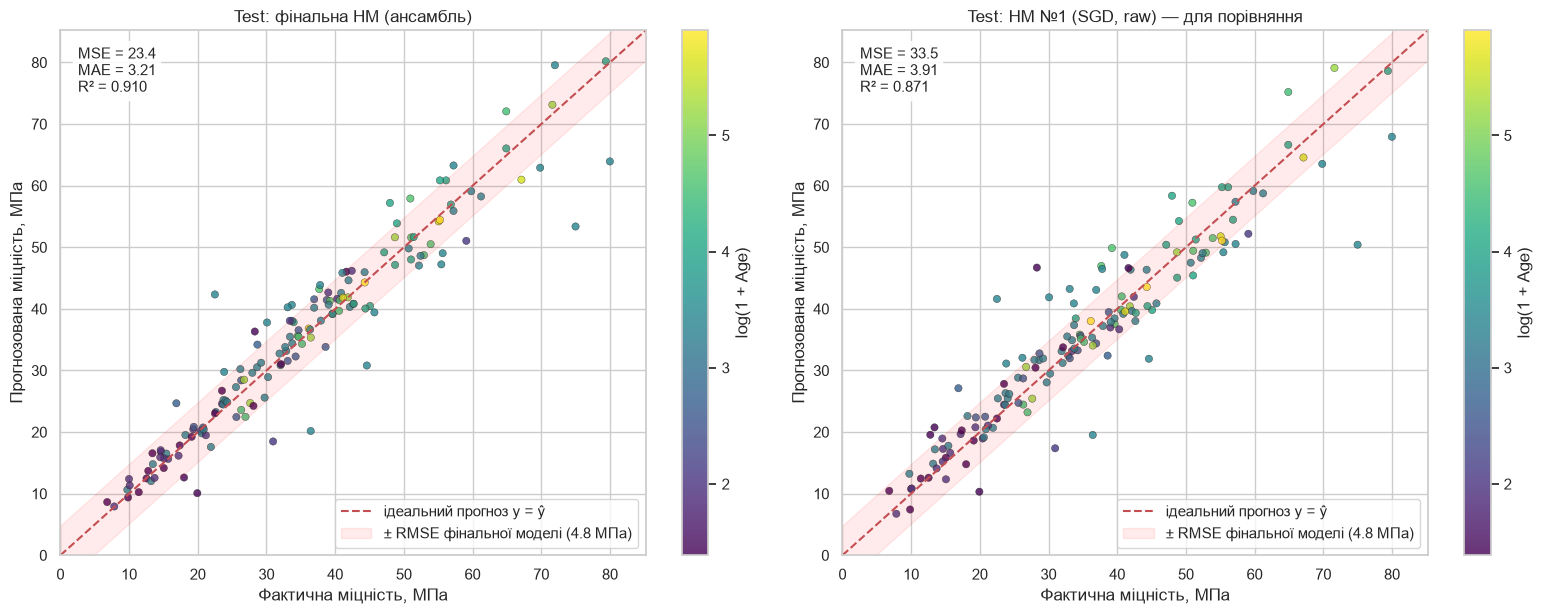

In [34]:
test_frame = data.iloc[idx_test].reset_index(drop=True).copy()
test_frame['pred'] = y_pred_test
test_frame['resid'] = test_frame[TARGET] - test_frame['pred']
rmse_t = final_test['RMSE']

fig, axes = plt.subplots(1, 2, figsize=(16, 6.3))
lims = [0, max(test_frame[TARGET].max(), test_frame['pred'].max()) + 5]
for ax, (title, y_true, y_hat, X_color) in zip(axes, [
        ('Test: фінальна НМ (ансамбль)', test_frame[TARGET], test_frame['pred'], test_frame['Age']),
        ('Test: НМ №1 (SGD, raw) — для порівняння', y_test, nn_test_pred['НМ №1: SGD lr=0.01, 64-32, raw'],
         test_frame['Age'])]):
    sc = ax.scatter(y_true, y_hat, c=np.log1p(X_color), cmap='viridis', s=28, alpha=0.8, edgecolor='k', lw=0.3)
    ax.plot(lims, lims, 'r--', lw=1.5, label='ідеальний прогноз y = ŷ')
    ax.fill_between(lims, np.array(lims) - rmse_t, np.array(lims) + rmse_t, color='red', alpha=0.08,
                    label=f'± RMSE фінальної моделі ({rmse_t:.1f} МПа)')
    m = regression_metrics(y_true, y_hat)
    ax.text(0.03, 0.97, f"MSE = {m['MSE']:.1f}\nMAE = {m['MAE']:.2f}\nR² = {m['R2']:.3f}", transform=ax.transAxes,
            va='top', fontsize=11, bbox=dict(boxstyle='round', fc='white', alpha=0.9))
    ax.set(xlim=lims, ylim=lims, xlabel='Фактична міцність, МПа', ylabel='Прогнозована міцність, МПа', title=title)
    ax.legend(loc='lower right')
    plt.colorbar(sc, ax=ax).set_label('log(1 + Age)')
plt.tight_layout()
plt.show()

- Прогнози фінальної моделі щільно лежать уздовж діагоналі y = ŷ в усьому діапазоні 7-80 МПа. У першої SGD-моделі (праворуч) розкид помітно більший, особливо в середньому діапазоні 20-50 МПа.
- Молоді (темні) і старі (жовті) зразки модель прогнозує однаково добре, систематичного зсуву за віком немає (детальніше в 9.4).
- На верхньому краю (> 70 МПа) модель схильна недооцінювати міцність. Високоміцних зразків у train мало, і модель «підтягує» їхній прогноз до середнього серед схожих сумішей.

### 9.3 Аналіз залишків

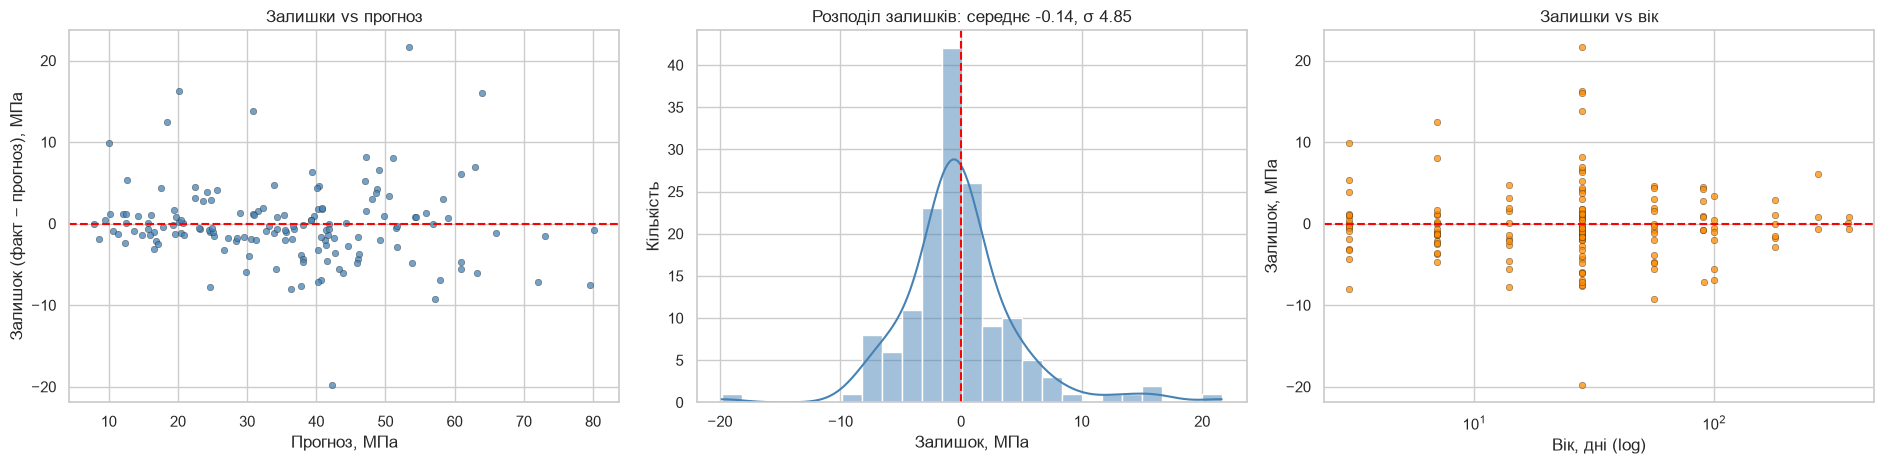

Частка тестових прогнозів з |помилкою| ≤ 5 МПа: 80.1%; ≤ 10 МПа: 96.0%


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
axes[0].scatter(test_frame['pred'], test_frame['resid'], s=22, alpha=0.75, color='steelblue', edgecolor='k', lw=0.3)
axes[0].axhline(0, color='red', ls='--')
axes[0].set(xlabel='Прогноз, МПа', ylabel='Залишок (факт − прогноз), МПа', title='Залишки vs прогноз')

sns.histplot(test_frame['resid'], bins=25, kde=True, ax=axes[1], color='steelblue')
axes[1].axvline(0, color='red', ls='--')
axes[1].set(xlabel='Залишок, МПа', ylabel='Кількість', title=(f"Розподіл залишків: середнє {test_frame['resid'].mean():.2f}, "
                                                            f"σ {test_frame['resid'].std():.2f}"))

axes[2].scatter(test_frame['Age'], test_frame['resid'], s=22, alpha=0.75, color='darkorange', edgecolor='k', lw=0.3)
axes[2].axhline(0, color='red', ls='--')
axes[2].set_xscale('log')
axes[2].set(xlabel='Вік, дні (log)', ylabel='Залишок, МПа', title='Залишки vs вік')
plt.tight_layout()
plt.show()

print(f"Частка тестових прогнозів з |помилкою| ≤ 5 МПа: {(test_frame['resid'].abs() <= 5).mean():.1%}; "
      f"≤ 10 МПа: {(test_frame['resid'].abs() <= 10).mean():.1%}")

- Залишки центровані біля нуля (середнє ≈ −0.1 МПа), тож систематичного зсуву немає. Розподіл симетричний, з гострим піком біля 0, але з «важкими хвостами»: є кілька помилок по 12-22 МПа.
- На графіку «залишки vs прогноз» немає ні тренду, ні явної «воронки». Дисперсія помилок приблизно стала в усьому діапазоні міцності (гетероскедастичність слабка).
- Найбільші за модулем залишки мають 28-добові зразки, найчисленніша й найрізноманітніша група.

### 9.4 Помилки за віковими групами

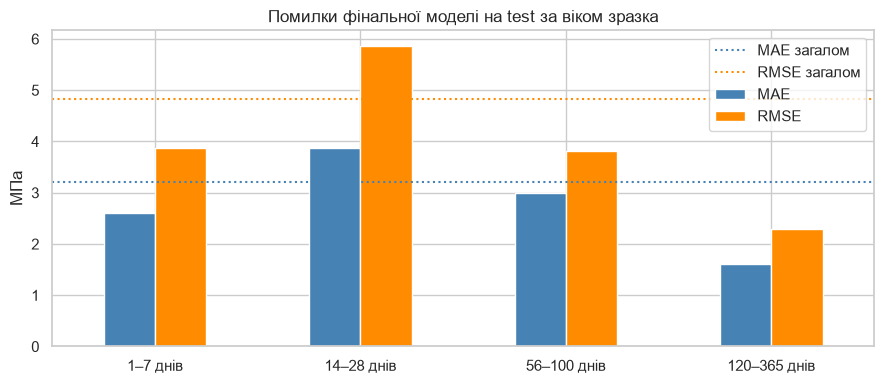

,n (test),n (train),середня міцність,MAE,RMSE,зсув (сер. залишок)
вікова група,,,,,,
1–7 днів,37,179,21.498,2.597,3.864,-0.031
14–28 днів,72,331,35.875,3.873,5.872,0.004
56–100 днів,30,154,46.769,2.994,3.807,-0.834
120–365 днів,12,39,46.001,1.615,2.301,0.358


In [36]:
AGE_BINS = [0, 7, 28, 100, 365]
AGE_LABELS = ['1–7 днів', '14–28 днів', '56–100 днів', '120–365 днів']
test_frame['вікова група'] = pd.cut(test_frame['Age'], bins=AGE_BINS, labels=AGE_LABELS)
by_age = test_frame.groupby('вікова група', observed=True).agg(**{
    'n (test)': ('resid', 'size'),
    'середня міцність': (TARGET, 'mean'),
    'MAE': ('resid', lambda r: r.abs().mean()),
    'RMSE': ('resid', lambda r: np.sqrt((r ** 2).mean())),
    'зсув (сер. залишок)': ('resid', 'mean'),
})
train_age_counts = pd.cut(data.iloc[idx_train]['Age'], bins=AGE_BINS, labels=AGE_LABELS).value_counts()
by_age.insert(1, 'n (train)', train_age_counts.reindex(by_age.index).to_numpy())

fig, ax = plt.subplots(figsize=(9, 4))
by_age[['MAE', 'RMSE']].plot.bar(ax=ax, rot=0, color=['steelblue', 'darkorange'])
ax.axhline(final_test['MAE'], color='steelblue', ls=':', label='MAE загалом')
ax.axhline(final_test['RMSE'], color='darkorange', ls=':', label='RMSE загалом')
ax.set(ylabel='МПа', title='Помилки фінальної моделі на test за віком зразка', xlabel='')
ax.legend()
plt.tight_layout()
plt.show()
by_age

- У групі 14-28 днів помилка найбільша (RMSE 5.9, MAE 3.9). Ця група найчисленніша й найрізноманітніша (у 28 діб випробовують майже всі рецептури), і саме в ній є аномальні зразки (див. 9.5).
- У групі 1-7 днів MAE 2.6 МПа. В абсолютних числах це мало, але відносно низької міцності в цьому віці (≈ 21 МПа) виходить ≈ 12 %.
- У групі 56-100 днів MAE 3.0 і легка переоцінка (зсув −0.8 МПа).
- У групі 120-365 днів помилка найменша (MAE 1.6), але в тесті лише 12 зразків (у train 39), тож оцінка ненадійна. Тут модель має найменше даних і найбільше екстраполює.
- В усіх групах |зсув| < 1 МПа. Отже, `log1p(Age)` добре описує кінетику набору міцності, і систематичної недо- чи переоцінки за віком немає.

### 9.5 Найбільші помилки

In [37]:
test_frame.reindex(test_frame['resid'].abs().sort_values(ascending=False).index)[
    BASE_FEATURES + ['WC', TARGET, 'pred', 'resid']].head(6)

,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,WC,Strength,pred,resid
96,522.000,0.000,0.000,146.000,0.000,896.000,896.000,28,0.280,74.990,53.374,21.616
68,381.400,0.000,0.000,185.700,0.000,"1,104.600",784.300,28,0.487,22.490,42.340,-19.850
30,139.900,132.600,103.300,200.300,7.400,916.000,753.400,28,1.432,36.440,20.177,16.263
54,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,0.300,79.990,63.931,16.059
12,141.900,166.600,129.700,173.500,10.900,882.600,785.300,28,1.223,44.610,30.809,13.801
71,297.000,0.000,0.000,186.000,0.000,"1,040.000",734.000,7,0.626,30.960,18.475,12.485


Майже всі найбільші промахи припадають на 28-добові зразки з нетиповим складом:
- 522 кг цементу, W/C = 0.28, без добавок: факт 75.0, прогноз 53.4. Дуже міцний бетон при низькому W/C без суперпластифікатора трапляється рідко. Та сама суміш у віці 7 діб є лише у validation, а інші суміші з 500+ кг цементу у 28 діб мають переважно 41-67 МПа. Модель прогнозує «типове» значення для такої групи.
- 381 кг цементу, W/C = 0.49, без добавок: факт 22.5, прогноз 42.3. Для такої суміші 22.5 МПа у 28 діб підозріло мало: схожі суміші (375-400 кг цементу, W/C 0.47-0.50, без шлаку й золи) у 28 діб мають 31-44 МПа (медіана ≈ 37). Модель тут трохи завищує, але основна причина помилки в аномальному вимірюванні.
- 540 кг цементу, W/C = 0.30: факт 80.0, прогноз 63.9. У train є майже ідентична суміш з міцністю 61.9 МПа (відрізняється лише крупним заповнювачем: 1055 замість 1040 кг), і прогноз фактично збігається з нею. Різниця 18 МПа між такими «близнюками» є шумом даних, модель тут ні до чого.

Частину найбільших помилок пояснюють шум і аномалії у вимірюваннях, яких жодна модель не передбачить. Саме вони роблять RMSE помітно більшим за MAE.

### 9.6 Які фактори найважливіші? Permutation importance

Вбудованих «важливостей» у нейромережі немає, тому я використовую permutation importance. Значення однієї вихідної ознаки в тестовій вибірці випадково перемішуються (так руйнується її зв'язок з ціллю), і я дивлюся, наскільки зросте MSE. Перемішуються 8 вихідних колонок, а інженерні `LogAge` / `WC` перераховуються з них, тож відповідь сформульована в термінах реальних матеріалів і віку. На кожну ознаку 30 повторів. Для порівняння те саме зроблено для Gradient Boosting.

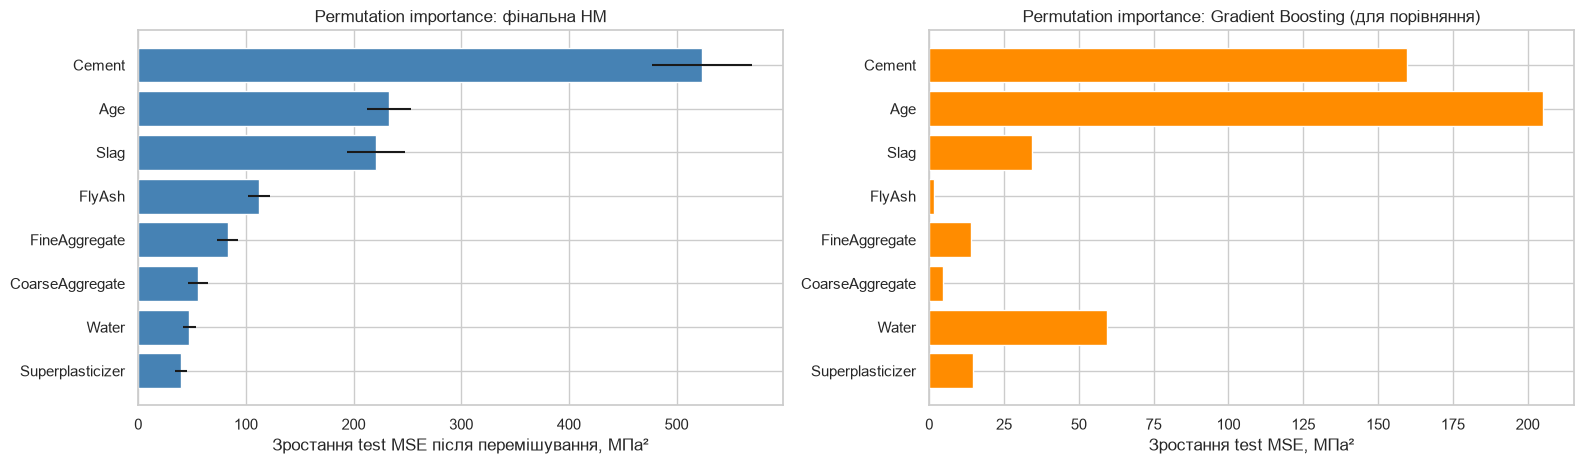

,ΔMSE (сер.),ΔMSE (σ),"частка, %",ΔMSE Gradient Boosting
Cement,523.725,46.652,39.791,159.560
Age,232.985,20.824,17.702,205.224
Slag,220.855,26.773,16.780,34.310
FlyAsh,112.260,10.469,8.529,1.592
FineAggregate,83.132,9.500,6.316,14.044
CoarseAggregate,55.853,9.328,4.244,4.465
Water,47.576,5.710,3.615,59.449
Superplasticizer,39.788,5.348,3.023,14.796


In [38]:
def make_frame_predictor(model, scaler, feature_set):
    """Full pipeline: raw 8-column frame -> engineered features -> scaling -> network prediction."""
    cols = FEATURE_SETS[feature_set]

    def predict_frame(frame: pd.DataFrame) -> np.ndarray:
        X = add_features(frame[BASE_FEATURES])[cols].to_numpy(dtype=np.float32)
        return predict(model, scaler.transform(X).astype(np.float32))
    return predict_frame


def permutation_importance_frame(predict_frame, frame, y, n_repeats=30, seed=SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    base_mse = mean_squared_error(y, predict_frame(frame))
    rows = {}
    for col in BASE_FEATURES:
        increases = []
        for _ in range(n_repeats):
            shuffled = frame.copy()
            shuffled[col] = rng.permutation(shuffled[col].to_numpy())
            increases.append(mean_squared_error(y, predict_frame(shuffled)) - base_mse)
        rows[col] = {'ΔMSE (сер.)': np.mean(increases), 'ΔMSE (σ)': np.std(increases)}
    return pd.DataFrame(rows).T.sort_values('ΔMSE (сер.)', ascending=False)


final_predict_frame = make_frame_predictor(final_model, final_scaler, FINAL_FS)
X_test_frame = data.iloc[idx_test][BASE_FEATURES].reset_index(drop=True)
imp_nn = permutation_importance_frame(final_predict_frame, X_test_frame, y_test)
imp_nn['частка, %'] = 100 * imp_nn['ΔMSE (сер.)'] / imp_nn['ΔMSE (сер.)'].clip(lower=0).sum()

gbm = reference['Gradient Boosting'][0]
pi_gbm = permutation_importance(gbm, X_te_u, y_test, n_repeats=30, random_state=SEED,
                                scoring='neg_mean_squared_error')
imp_gbm = pd.Series(pi_gbm.importances_mean, index=BASE_FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
order = imp_nn.index[::-1]
axes[0].barh(order, imp_nn.loc[order, 'ΔMSE (сер.)'], xerr=imp_nn.loc[order, 'ΔMSE (σ)'], color='steelblue')
axes[0].set(xlabel='Зростання test MSE після перемішування, МПа²', title='Permutation importance: фінальна НМ')
axes[1].barh(order, imp_gbm.reindex(order), color='darkorange')
axes[1].set(xlabel='Зростання test MSE, МПа²', title='Permutation importance: Gradient Boosting (для порівняння)')
plt.tight_layout()
plt.show()
imp_nn.assign(**{'ΔMSE Gradient Boosting': imp_gbm.reindex(imp_nn.index)})

Рейтинг факторів за permutation importance:

| Ранг | Нейромережа (фінальна) | Gradient Boosting |
|---|---|---|
| 1 | Cement | Age |
| 2 | Age | Cement |
| 3 | Slag | Water |
| 4 | FlyAsh | Slag |

- Обидві моделі незалежно ставлять цемент і вік на перші два місця. Це узгоджується з кореляціями з EDA і з технологією бетону. Цемент є основним в'яжучим: що більше цементу, то більше продуктів гідратації і то щільніший цементний камінь. Міцність зростає з віком у міру гідратації (≈ логарифмічно, основний набір відбувається за перші 28 діб).
- У мережі далі йдуть інші компоненти в'яжучого, шлак і зола. Вони частково замінюють цемент і набирають міцність повільніше (латентно-гідравлічна та пуцоланова реакції), тож мережа оцінює внесок в'яжучого в цілому. GBM на 3-тє місце ставить воду, і це прямо випливає із закону Абрамса: більше води при тому ж цементі дає вищий W/C, більшу пористість і нижчу міцність.
- Суперпластифікатор опинився в нижній частині рейтингу обох моделей, хоча його кореляція з міцністю +0.37. Він діє опосередковано, бо дозволяє зменшити воду. Коли вода вже відома моделі, власний внесок добавки малий (див. PDP у 10.1). Кореляцію +0.37 він значною мірою «позичає» через зв'язок з водою (r = −0.66).
- У методу є обмеження. Перемішування однієї ознаки створює нереалістичні суміші (напр., 540 кг цементу + 300 кг шлаку + 200 кг золи). Мережа з лінійним виходом екстраполює такі входи майже лінійно і дає дуже великі помилки (ΔMSE для цементу ≈ 520, більше за дисперсію цілі), а дерева обмежують прогноз діапазоном train. Тому абсолютні ΔMSE двох моделей я не порівнюю, лише ранги, а висновки перевіряю кривими часткової залежності (10.1).

## 10. Креативний аналіз (бонус)

### 10.1 Що «вивчила» мережа: криві часткової залежності (PDP + ICE)

Для кожного фактора я змінюю його значення по сітці для всіх зразків одночасно (інші ознаки лишаються реальними) і усереднюю прогноз мережі. Так виходить крива часткової залежності (PDP, товста лінія). Тонкі лінії (ICE) показують ті самі криві для 40 окремих сумішей. Якщо вони не паралельні, фактор взаємодіє з іншими.

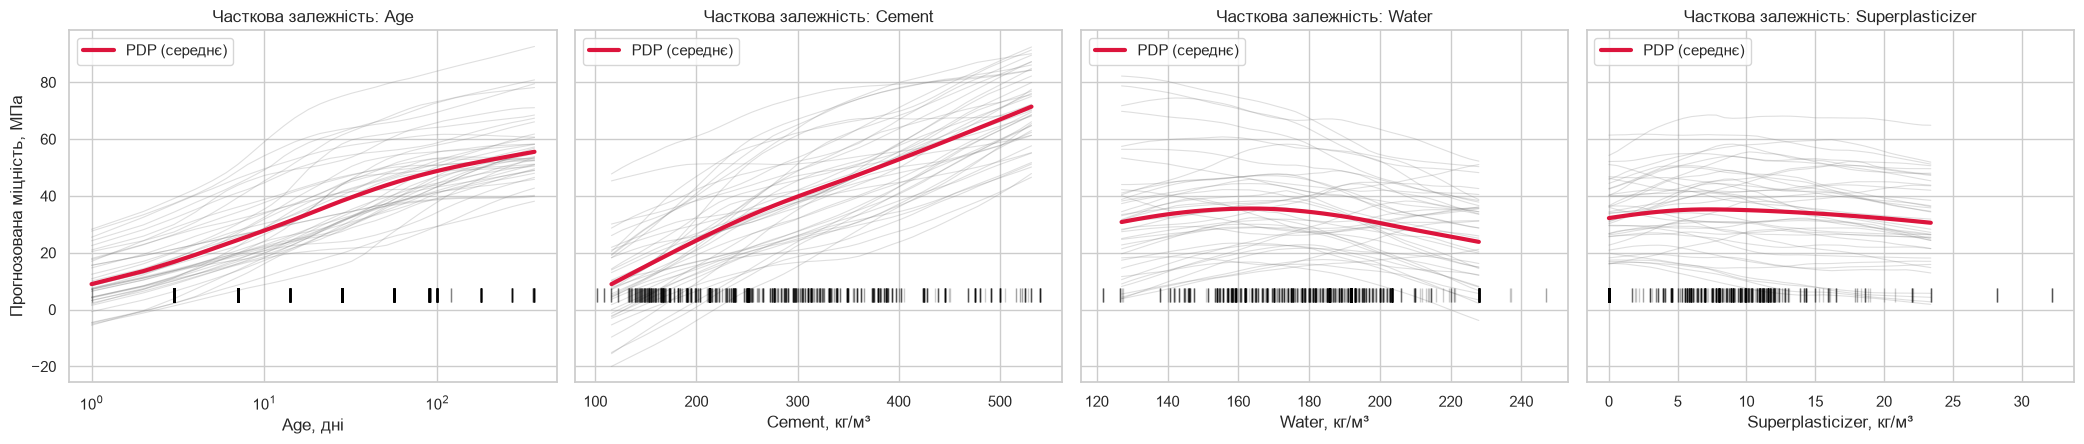

Age              : PDP від   9.0 до  55.5 МПа (Δ = +46.6) на діапазоні 1–365 дні
Cement           : PDP від   9.0 до  71.4 МПа (Δ = +62.5) на діапазоні 116–531 кг/м³
Water            : PDP від  30.8 до  23.8 МПа (Δ =  -7.0) на діапазоні 127–228 кг/м³
Superplasticizer : PDP від  32.2 до  30.6 МПа (Δ =  -1.6) на діапазоні 0–23 кг/м³


In [39]:
def pdp_ice(predict_frame, background: pd.DataFrame, col: str, grid: np.ndarray) -> np.ndarray:
    """ICE matrix (n_rows x len(grid)); PDP = its column mean."""
    bg = background.reset_index(drop=True)
    rep = bg.loc[bg.index.repeat(len(grid))].copy()
    rep[col] = np.tile(grid, len(bg))
    return predict_frame(rep).reshape(len(bg), len(grid))


background = data[BASE_FEATURES]
rng = np.random.default_rng(SEED)
ice_rows = rng.choice(len(background), size=40, replace=False)
pdp_specs = {
    'Age': np.unique(np.round(np.geomspace(1, 365, 40))),
    'Cement': np.linspace(*background['Cement'].quantile([0.01, 0.99]), 40),
    'Water': np.linspace(*background['Water'].quantile([0.01, 0.99]), 40),
    'Superplasticizer': np.linspace(0, background['Superplasticizer'].quantile(0.99), 40),
}

fig, axes = plt.subplots(1, 4, figsize=(21, 4.6), sharey=True)
pdp_curves = {}
for ax, (col, grid) in zip(axes, pdp_specs.items()):
    ice = pdp_ice(final_predict_frame, background, col, grid)
    pdp_curves[col] = (grid, ice.mean(0))
    ax.plot(grid, ice[ice_rows].T, color='grey', alpha=0.25, lw=0.8)
    ax.plot(grid, ice.mean(0), color='crimson', lw=3, label='PDP (середнє)')
    ax.plot(background[col], np.full(len(background), 5), '|', color='black', alpha=0.2, ms=10)  # data rug
    if col == 'Age':
        ax.set_xscale('log')
    ax.set(xlabel=f'{col}, {UNITS[col]}', title=f'Часткова залежність: {col}')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Прогнозована міцність, МПа')
plt.tight_layout()
plt.show()

for col, (grid, pdp) in pdp_curves.items():
    print(f'{col:17s}: PDP від {pdp[0]:5.1f} до {pdp[-1]:5.1f} МПа (Δ = {pdp[-1] - pdp[0]:+5.1f}) '
          f'на діапазоні {grid[0]:.0f}–{grid[-1]:.0f} {UNITS[col]}')

- За віком (`Age`) прогноз зростає монотонно, майже лінійно на log-осі до ≈ 100 діб (9 → ≈ 49 МПа), а далі повільніше (≈ 55 МПа на 365 добу). Мережа відтворила відому криву набору міцності. У сирих середніх з EDA (3.5) після 91 доби були «провали», а тут їх немає, бо PDP усуває змішування віку зі складом.
- Цемент (`Cement`) дає найсильніший ефект: від ≈ 9 до ≈ 71 МПа на діапазоні 116-531 кг/м³, майже лінійно (≈ +15 МПа на кожні 100 кг цементу).
- Для води (`Water`) є слабкий максимум біля ≈ 160 кг/м³, далі прогноз спадає: +70 кг води (160 → 228) знижують його ≈ на 12 МПа. Лівіше 150 кг даних мало (там суміші з великою дозою суперпластифікатора).
- Крива для суперпластифікатора (`Superplasticizer`) майже пласка (≈ 31-35 МПа). При фіксованій воді добавка майже не додає міцності, її реальна користь у тому, що вона дозволяє зменшити воду за тієї ж рухливості суміші. З простої кореляції (+0.37) цього не видно, а з технологією бетону це узгоджується.
- ICE-лінії не паралельні, особливо для віку та цементу, тобто фактори взаємодіють (наприклад, суміші зі шлаком і золою довше набирають міцність). Тому нелінійна модель тут виправдана. Окремі ICE-лінії для віку 1 доба опускаються нижче 0 через необмежений лінійний вихід (див. 10.2).

### 10.2 Карта «цемент × вік»: скільки цементу потрібно для заданої міцності

Карта показує прогноз мережі для «типової» суміші, у якій змінюються лише кількість цементу та вік, а всі інші компоненти дорівнюють медіанам train. Ізолінії з'єднують комбінації з однаковою прогнозованою міцністю. Білі точки є реальними зразками train: за ними видно, де модель має дані, а де екстраполює.

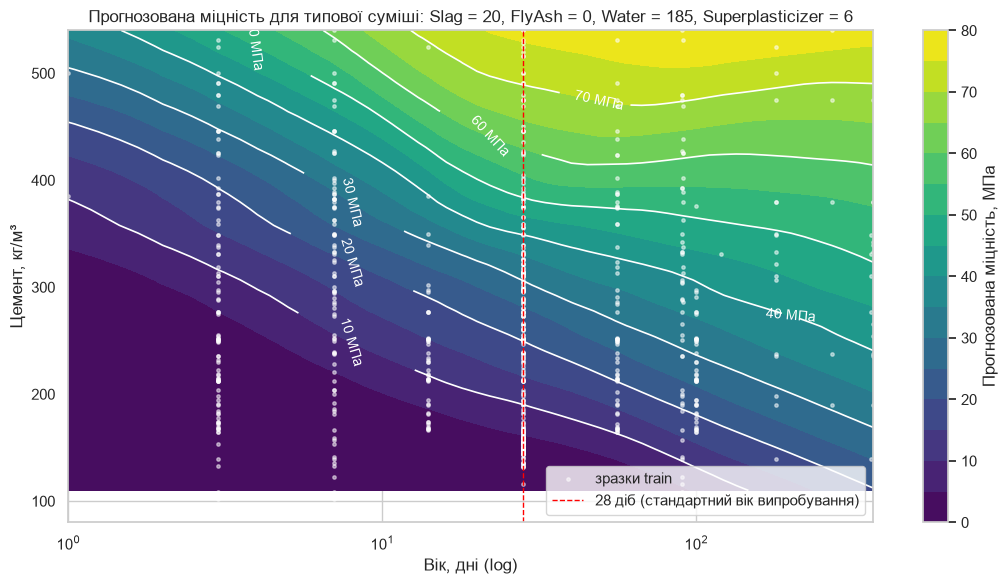

Для 30 МПа у 28 діб типовій суміші потрібно цементу: ≈ 314 кг/м³ (W/C ≈ 0.59)
Для 40 МПа у 28 діб типовій суміші потрібно цементу: ≈ 351 кг/м³ (W/C ≈ 0.53)
Мінімальний прогноз на сітці: -23.8 МПа (частка точок сітки з прогнозом < 0: 7.9%) — від'ємні значення фізично неможливі, це екстраполяція; на карті обрізано на 0


In [40]:
ref_mix = data.iloc[idx_train][BASE_FEATURES].median()
cement_grid = np.linspace(110, 540, 60)
age_grid = np.unique(np.round(np.geomspace(1, 365, 60)))
mesh = pd.DataFrame(np.tile(ref_mix.to_numpy(), (len(cement_grid) * len(age_grid), 1)), columns=BASE_FEATURES)
mesh['Cement'] = np.repeat(cement_grid, len(age_grid))
mesh['Age'] = np.tile(age_grid, len(cement_grid))
Z = final_predict_frame(mesh).reshape(len(cement_grid), len(age_grid))

fig, ax = plt.subplots(figsize=(11, 6))
cf = ax.contourf(age_grid, cement_grid, Z.clip(min=0), levels=np.arange(0, 85, 5), cmap='viridis')  # <0 is unphysical
cs = ax.contour(age_grid, cement_grid, Z, levels=[10, 20, 30, 40, 50, 60, 70], colors='white', linewidths=1.2)
ax.clabel(cs, fmt='%d МПа', fontsize=10)
train_pts = data.iloc[idx_train]
ax.scatter(train_pts['Age'], train_pts['Cement'], s=6, color='white', alpha=0.5, label='зразки train')
ax.axvline(28, color='red', ls='--', lw=1, label='28 діб (стандартний вік випробування)')
ax.set_xscale('log')
ax.set(xlabel='Вік, дні (log)', ylabel='Цемент, кг/м³',
       title=('Прогнозована міцність для типової суміші: ' +
              ', '.join(f'{c} = {ref_mix[c]:.0f}' for c in ['Slag', 'FlyAsh', 'Water', 'Superplasticizer'])))
plt.colorbar(cf, ax=ax).set_label('Прогнозована міцність, МПа')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

i28 = np.argmin(np.abs(age_grid - 28))
for target_mpa in (30, 40):
    ok = np.where(Z[:, i28] >= target_mpa)[0]
    need = (f'≈ {cement_grid[ok[0]]:.0f} кг/м³ (W/C ≈ {ref_mix["Water"] / cement_grid[ok[0]]:.2f})'
            if len(ok) else 'не досягається в діапазоні сітки')
    print(f'Для {target_mpa} МПа у 28 діб типовій суміші потрібно цементу: {need}')
print(f'Мінімальний прогноз на сітці: {Z.min():.1f} МПа (частка точок сітки з прогнозом < 0: {(Z < 0).mean():.1%}) '
      '— від\'ємні значення фізично неможливі, це екстраполяція; на карті обрізано на 0')

- Ізолінії спадають зліва направо: ту саму міцність дає або більша кількість цементу, або довше витримування. Для типової суміші (вода 185, суперпластифікатор 6, шлак 20 кг/м³) мережа оцінює, що для 30 МПа у 28 діб потрібно ≈ 314 кг цементу (W/C ≈ 0.59), а для 40 МПа ≈ 351 кг (W/C ≈ 0.53). Значення правдоподібні: у звичайних бетонних сумішах зазвичай 250-400 кг цементу на м³, а W/C ≈ 0.5-0.6.
- Після ≈ 90-100 діб ізолінії стають пологими, і подальше витримування додає мало.
- Карта показує й обмеження моделі. У лівому нижньому куті (мало цементу, ранній вік) мережа прогнозує від'ємну міцність (мінімум ≈ −24 МПа, ≈ 8 % точок сітки). Навчальних даних для такої суміші немає (реальні суміші з малим цементом містять багато шлаку/золи), а лінійний вихід нічим не обмежений. На карті ці значення обрізано на 0. Прогнозам поза областю даних довіряти не можна. Виправити це можна через `Softplus` на виході або прогноз `log(Strength)`.

### 10.3 Перевірка на нових рецептурах: чи узагальнює модель?

У випадковому розбитті та сама суміш (7 компонентів), випробувана в різному віці, може потрапити і в train, і в test. Тоді модель «знає» рецептуру й лише інтерполює вік. На практиці модель потрібна для нових сумішей. Тому я повторюю навчання фінальної конфігурації з груповим розбиттям за рецептурою (`GroupShuffleSplit`, ≈ 70 / 15 / 15 за групами), щоб жодна рецептура тесту не траплялася в train. Для порівняння на тому ж розбитті навчено Gradient Boosting.

In [41]:
recipe_id = data.groupby(MIX_COLS, sort=False).ngroup().to_numpy()
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
g_tr, g_tmp = next(gss.split(idx_all, groups=recipe_id))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
g_va_rel, g_te_rel = next(gss2.split(g_tmp, groups=recipe_id[g_tmp]))
g_va, g_te = g_tmp[g_va_rel], g_tmp[g_te_rel]
assert not set(recipe_id[g_tr]) & set(recipe_id[g_te])     # no shared recipes between train and test

final_cfg = {k: v for k, v in final_single['cfg'].items() if k != 'seed'}
group_members = [run_experiment(**final_cfg, seed=s, split=(g_tr, g_va, g_te)) for s in SEEDS]
group_ens = EnsembleNet([r['model'] for r in group_members])
group_nn = regression_metrics(y_all[g_te], predict(group_ens, group_members[0]['X']['test']))

gbm_group = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8,
                                      random_state=SEED).fit(X_raw_unscaled[g_tr], y_all[g_tr])
group_gbm = regression_metrics(y_all[g_te], gbm_group.predict(X_raw_unscaled[g_te]))

pd.DataFrame({
    'НМ (ансамбль), випадкове розбиття': final_test,
    'НМ (ансамбль), розбиття за рецептурою': group_nn,
    'Gradient Boosting, випадкове розбиття': test_table.loc['Gradient Boosting', ['MSE', 'RMSE', 'MAE', 'R2']].astype(float),
    'Gradient Boosting, розбиття за рецептурою': group_gbm,
}).T.assign(**{'n train / test': [f'{len(idx_train)} / {len(idx_test)}', f'{len(g_tr)} / {len(g_te)}'] * 2})

,MSE,RMSE,MAE,R2,n train / test
"НМ (ансамбль), випадкове розбиття",23.400,4.837,3.206,0.910,703 / 151
"НМ (ансамбль), розбиття за рецептурою",33.179,5.760,3.854,0.890,684 / 170
"Gradient Boosting, випадкове розбиття",20.866,4.568,2.951,0.920,703 / 151
"Gradient Boosting, розбиття за рецептурою",36.357,6.030,4.304,0.879,684 / 170


- Коли тестові рецептури повністю нові, помилка мережі зростає: MSE 23.4 → 33.2, R² 0.910 → 0.890. Отже, випадкове розбиття дещо оптимістичне: частина «якості» береться з того, що модель бачила ту саму суміш в іншому віці.
- Проте й на нових рецептурах мережа лишається в зоні «відмінно» (MSE < 35, MAE ≈ 3.9, R² ≈ 0.89). Тобто модель вивчила саму залежність міцності від складу і на незнайомих сумішах теж працює.
- Gradient Boosting погіршується сильніше (20.9 → 36.4) і на нових рецептурах поступається мережі. Дерева добре «запам'ятовують» відомі комбінації, а мережа вивчає гладкі залежності, які краще переносяться на нові суміші. Але це одне розбиття (170 тестових зразків), тож висновок попередній. Для надійності потрібна групова крос-валідація (`GroupKFold`).

In [42]:
print(f'Загальний час виконання ноутбука: {time.time() - NOTEBOOK_START:.0f} с')

Загальний час виконання ноутбука: 97 с


## 11. Висновки

### 11.1 Результати

| Метрика | Фінальна НМ (ансамбль): test | Фінальна НМ: validation | Перша НМ (SGD, 8 ознак): test | Орієнтир «відмінно» | Оцінка фінальної |
|---|---|---|---|---|---|
| MSE, МПа² | 23.4 (95 % ДІ ≈ 15-34) | 18.0 | 33.5 | < 35 | відмінно |
| RMSE, МПа | 4.84 | 4.24 | 5.79 | | |
| MAE, МПа | 3.21 | 2.90 | 3.91 | < 5 | відмінно |
| R² | 0.910 | 0.938 | 0.871 | > 0.8 | відмінно |

- Навчання проходить стабільно: усі мережі збігаються за 100-300 епох (Adam, lr = 0.01). На validation фінальна модель досягає MSE ≈ 18, R² ≈ 0.94. Розрив між train (MSE ≈ 4) і validation/test (18-23) вказує на помірне перенавчання, яке стримує рання зупинка з поверненням найкращих ваг.
- Уже перша модель, зроблена строго за інструкцією (SGD, lr = 0.01, 8 ознак), потрапляє в зону «відмінно». Оптимізація зменшила test MSE ще на ≈ 30 % (33.5 → 23.4).
- Нейромережа в 2.4-4.3 раза точніша за лінійну регресію, працює на рівні Random Forest і на випадковому розбитті статистично не відрізняється від Gradient Boosting. На нових рецептурах вона узагальнює краще за GBM (MSE 33.2 vs 36.4).

### 11.2 Що спрацювало, а що ні
1. Підготовка даних без витоку: видалено 25 дублікатів, щоб копії не опинилися одночасно в train і test, `StandardScaler` навчено лише на train, розбиття стратифіковане 70 / 15 / 15, а всі рішення ухвалено лише за validation.
2. `log1p(Age)` виявився найпростішим і найкориснішим покращенням (−16 % val MSE), бо ця ознака відповідає логарифмічній кінетиці набору міцності.
3. Adam з lr = 0.01 разом з ранньою зупинкою навчається швидше, стабільніше й точніше за SGD. SGD з momentum чутливий до lr і при 0.01 «ламає» мережу (мертві ReLU / NaN).
4. Архітектура 64-32 має помірний розмір. Одного шару 32 замало, а 128-64-32 завелика для ≈ 700 прикладів.
5. Ініціалізація bias середнім і ансамбль 3 seed коштують мало, але стабілізують навчання і прогноз.
6. Не спрацювали `W/C` як додаткова ознака (мережа сама будує комбінацію води й цементу), а також Dropout і weight decay (рання зупинка вже достатньо регуляризує маленьку мережу).

### 11.3 Найважливіші фактори
Для обох моделей (НМ і GBM) найважливіші **цемент і вік**. За ними йдуть інші компоненти в'яжучого (шлак, зола) та вода. Суперпластифікатор впливає опосередковано, через зменшення води. Це відповідає технології бетону: міцність визначають кількість в'яжучого, водоцементне відношення (закон Абрамса) та тривалість гідратації. За кривими часткової залежності кожні 100 кг цементу додають ≈ +15 МПа, з віком міцність росте логарифмічно до ≈ 100 діб, а коли води більше ніж ≈ 160 кг/м³, міцність спадає.

### 11.4 Критична оцінка підходу та обмеження
- MLP 64-32 з лінійним виходом є простим і адекватним вибором для 8 числових ознак, але архітектура має недоліки: (а) вихід не обмежений знизу, тому поза областю даних модель дає від'ємну міцність (10.2); (б) мережа не «знає» фізичних закономірностей (монотонність за цементом і віком) і вивчає їх лише з даних; (в) при перемішуванні ознак вона сильно екстраполює (9.6), тобто чутлива до нереалістичних комбінацій входів; (г) перенавчання помітне (train 4 vs test 23).
- Датасет малий: 1005 рядків і лише 427 унікальних рецептур. 41 % зразків 28-добові, старших за 100 діб лише ≈ 6 %, а високоміцних (> 70 МПа) одиниці. У цих зонах модель екстраполює і, зокрема, недооцінює найміцніші бетони.
- У даних є шум і аномалії. Повторні випробування тієї самої суміші відрізняються на 1-8 МПа, майже ідентичні суміші до 18 МПа, є явні аномалії (22.9 vs 55.9 МПа). Цей шум задає нижню межу помилки для будь-якої моделі і є головним джерелом великих промахів.
- Оцінка має обмежену надійність. Validation (151 приклад) використано для багатьох порівнянь, тому її метрики оптимістичні. Test теж малий: 95 % інтервал для MSE ≈ 15-34 МПа². Випадкове розбиття завищує якість приблизно на 10 МПа² порівняно з новими рецептурами (10.3).
- У самих даних вік змішаний зі складом (старі зразки переважно є сумішами без суперпластифікатора з великою кількістю води), і через це вплив віку важко оцінити окремо.

### 11.5 Шляхи покращення
1. Перейти на крос-валідацію `GroupKFold` за рецептурою замість одного val-розбиття, і для вибору гіперпараметрів, і для точнішої оцінки.
2. Перенавчити фінальну модель на train + val з кількістю епох, знайденою ранньою зупинкою (+15 % даних для навчання).
3. Збільшити ансамбль (5-10 seed) або зробити стекінг НМ + Gradient Boosting. Ці моделі помиляються по-різному: НМ краща на нових рецептурах, GBM на відомих.
4. Додати фізичні обмеження: `Softplus` на виході або прогноз `log(Strength)` для невід'ємності, монотонні обмеження за віком і цементом.
5. Спробувати доменні ознаки: відношення вода / в'яжуче `W/B = Water / (Cement + Slag + FlyAsh)`, частки компонентів у суміші, взаємодії `LogAge × Slag` / `LogAge × FlyAsh` (повільні добавки).
6. Разом з доменним експертом почистити дані: перевірити аномальні повтори і майже-дублікати. Також можна спробувати Huber loss, він стійкіший до поодиноких викидів.
7. Тонше налаштувати навчання: планувальник lr (`ReduceLROnPlateau` / cosine), `AdamW`, BatchNorm, автоматичний пошук гіперпараметрів (Optuna).
8. Зібрати більше даних для рідкісних зон: вік > 100 діб, високоміцні бетони > 70 МПа.